# Compact left-aligned mixed-length training — sequence PE: **LEARNED absolute 1D position/slot tables (the legacy default used in notebooks 01-06)**

**Question.** Models are trained FROM SCRATCH only on final outputs of composite instructions (effective lengths
0, 2, 3, 4, 5; **never** a single operation) and tested on the never-trained single operations A, B, C.

**Training support (identical in notebooks 07 and 08; 361 words):** EMPTY; all 9 length-2 words (AA..CC); all 27
length-3, 81 length-4 and 243 length-5 words. Lengths are sampled 20% each and words are balanced within a length.
The budget is seed 42, 5000 updates x batch 256 = 1,280,000 examples per run. Every model and both PE conditions see
the SAME logical example sequence.

**Compact layout.** The j-th operation always occupies slot j; the remaining slots are PAD (masked as attention
keys). Grid and output tokens keep fixed offsets (AR: 82 tokens, `<OUTPUT>` at 44, answers 45..80, `<EOS>` 81).
There is no random placement in these runs.

**The ONLY difference between 07 and 08 is the 1D sequence positional encoding of the seven attention models.**
Both use the same deterministic layout position IDs and keep the same additive grid row/column (ViT: patch
row/column) and segment/type embeddings. Neither has a learned 1D position or slot table. This controls 1D sequence
PE conditional on the shared spatial encoding; it is not a comparison of 2D schemes.

**Shared CNN controls.** ResCNN-FiLM and U-Net-FiLM have no attention PE. They are trained once in `shared_cnn/` and
reused by whichever notebook runs second, but only when the configuration hashes match. They are reported once and
are n/a for the PE contrast.

**Test.** The selected checkpoint (lowest length-macro validation CE on lengths 0/2/3/4/5) is evaluated on all 364
words of length 0..5 x 1000 held-out grids, using compact left alignment. AR decoding is free-running. Lengths 2-5 are
seen strings on new grids; the singles are the only held-out strings.

**Limits.** One seed. Differences from notebooks 04/05 change BOTH the placement distribution and the PE, so they do
not isolate placement. Behavioural diagnostics are non-causal.

> **Notebook 09 (learned 1D PE).** Same data, layout, manifests, budget and shared CNN controls as 07/08. The seven
> attention models use the legacy *trainable* 1D tables instead (AR: one vector per layout position; encoder / ViT / TRM:
> one vector per operation slot). Together with notebook 05 (random placement + learned PE, same 361-word support)
> this separates **placement** (05 vs 09: same learned PE) from **PE type** (09 vs 07/08: same compact placement).
> The learned tables add trainable parameters, so 09 is not parameter-identical to 07/08. One seed.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: a148085c7359ba06c019910a01c67a6b033a95ed


In [2]:
# --- CONFIGURATION ---------------------------------------------------------------------------------------
PE = "learned"                                   # 1D sequence PE for the attention models of THIS notebook
MODE = os.environ.get("DECOMP_MODE", "full")  # "full" = requested benchmark | "smoke" = tiny CPU integration run
SEED = 42
ATTN_MODELS = os.environ.get("DECOMP_ATTN_MODELS", "transformer_ar,looped_transformer_ar,transformer_encoder,"
                             "looped_transformer_encoder,vit,looped_vit,trm").split(",")
CNN_CONTROLS = os.environ.get("DECOMP_CNN_MODELS", "rescnn_film,unet_film").split(",")
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
COMPACT_ROOT = f"{RESULTS_ROOT}/compact_02345_pe"   # NEW subtree (manifests/, rope/, sinusoidal/, shared_cnn/, comparisons/)
RESUME = True
OPTIMIZER_STEPS = None          # None = mode default (full: 5000)
EFFECTIVE_BATCH = None          # None = mode default (full: 256)
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
MICROBATCH = None
EVAL_CHUNK_GRIDS = 100
ANALYSIS_CHUNK_SIZE = 2000
USE_ANALYSIS_CACHE = True
RUN_PROFILE = True
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
from decompositionality.config import make_experiment_config
_over = dict(seed=SEED, device=DEVICE, dtype=DTYPE, microbatch_size=MICROBATCH)
if OPTIMIZER_STEPS: _over["optimizer_steps"] = OPTIMIZER_STEPS
if EFFECTIVE_BATCH: _over["effective_batch_size"] = EFFECTIVE_BATCH
cfg_pe = make_experiment_config(f"compact_02345_{PE}", MODE, COMPACT_ROOT, ATTN_MODELS, **_over)
cfg_cnn = make_experiment_config("compact_02345_cnn", MODE, COMPACT_ROOT, CNN_CONTROLS, **_over)
for c in (cfg_pe, cfg_cnn):
    c.resume = RESUME
if MODE == "smoke":
    print("*** SMOKE MODE: tiny integration run; NOT scientific results ***")
print(f"PE={PE} | mode={MODE} | steps={cfg_pe.train.optimizer_steps} | batch={cfg_pe.train.effective_batch_size} | "
      f"seed={SEED} | slots={cfg_pe.n_slots} | placement=compact_left")
print("attention runs ->", cfg_pe.experiment_dir, "| shared CNN controls ->", cfg_cnn.experiment_dir,
      "| shared manifests ->", cfg_pe.manifest_dir)


Mounted at /content/drive
PE=learned | mode=full | steps=5000 | batch=256 | seed=42 | slots=5 | placement=compact_left
attention runs -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/learned | shared CNN controls -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/shared_cnn | shared manifests -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests


In [3]:
import json, torch
from decompositionality.utils import environment_info
ENV_INFO = environment_info(REPO_DIR)
print(json.dumps(ENV_INFO, indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "a148085c7359ba06c019910a01c67a6b033a95ed",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 39.49
}


In [4]:
# --- Validate supports, compact layout, offsets, learned-PE wiring and manifests --------------------------------
import dataclasses, hashlib
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from decompositionality import mixed as M, tokenization as T
from decompositionality.mixed_pipeline import prepare_mixed
from decompositionality.models.registry import build_model, default_config
sup = M.support(cfg_pe.experiment)
assert {L: len(w) for L, w in sup.items()} == {0: 1, 2: 9, 3: 27, 4: 81, 5: 243} and len(cfg_pe.train_strings) == 361
assert len(M.test_words()) == 364 and not any(len(w) == 1 for w in M.training_words(cfg_pe.experiment))
lay = T.ARLayout(5)
assert (lay.length, lay.idx_output, lay.out_start, lay.out_start + 35, lay.idx_eos) == (82, 44, 45, 80, 81)
_s = M.MixedTrainStream(SEED, cfg_pe.experiment, 256)
_o = M.MixedTrainStream(SEED, "compact_02345_rope", 256)
for step in (0, 1, 2):
    a, b = _s.batch(step), _o.batch(step)
    assert all(np.array_equal(a[k], b[k]) for k in ("x", "y", "ops", "string", "length")), "data differs from 07/08"
    for ops, L in zip(a["ops"], a["length"]):
        assert (ops[:L] != 3).all() and (ops[L:] == 3).all(), "not compact left-aligned"
print("compact left alignment + identical logical data stream to notebooks 07/08: OK")
rows = []
for m in ATTN_MODELS:
    c = dataclasses.asdict(default_config(m)); c.update(n_slots=5, sequence_pe="learned")
    mod = build_model(m, c, seed=SEED)
    names = [k for k, _ in mod.named_parameters()]
    assert any(k.startswith(("pos_emb", "slot_emb")) for k in names), f"{m}: learned 1D table missing"
    assert not hasattr(mod, "seq_pe"), f"{m}: rope/sinusoidal tables must not be present"
    rows.append({"model": m, "unique_params": sum(p.numel() for p in mod.parameters()),
                 "learned_1d_tables": ", ".join(k for k in names if k.startswith(("pos_emb", "slot_emb")))})
init_df = pd.DataFrame(rows); display(init_df)
ctx_pe = prepare_mixed(cfg_pe, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json")
ctx_cnn = prepare_mixed(cfg_cnn, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json")
assert ctx_pe.manifests.manifest_hash == ctx_cnn.manifests.manifest_hash
cfg_pe.experiment_dir.mkdir(parents=True, exist_ok=True)
init_df.to_csv(cfg_pe.experiment_dir / "initialization_checksums.csv", index=False)
print("validation records per length:", pd.Series(ctx_pe.val_set["length"]).value_counts().sort_index().to_dict())


compact left alignment + identical logical data stream to notebooks 07/08: OK


,model,unique_params,learned_1d_tables
0,transformer_ar,10702099,pos_emb.weight
1,looped_transformer_ar,1829779,pos_emb.weight
2,transformer_encoder,10664074,slot_emb.weight
3,looped_transformer_encoder,1791754,slot_emb.weight
4,vit,10685224,slot_emb.weight
5,looped_vit,1812904,slot_emb.weight
6,trm,9939840,slot_emb


Manifests /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 records (300 grids x 5 lengths) | fixed validation subset 160 | test 364,000 (1000 grids x 364 words)
Manifests /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 records (300 grids x 5 lengths) | fixed validation subset 160 | test 364,000 (1000 grids x 364 words)
validation records per length: {0: 300, 2: 300, 3: 300, 4: 300, 5: 300}


In [5]:
# --- Parameter counts / time estimate -------------------------------------------------------------------------
from decompositionality.mixed_reports import resource_table
from decompositionality.training import profile_model
display(resource_table(cfg_pe.experiment_dir, cfg_pe.experiment_dir / "tables", PE, ATTN_MODELS))
if RUN_PROFILE and torch.cuda.is_available():
    prof = pd.DataFrame([profile_model(m, cfg_pe.train, n_steps=2, n_slots=5, sequence_pe=PE) for m in ATTN_MODELS])
    display(prof)


,model,display_name,n_slots,sequence_pe,unique_learned_params,shared_core_params,untied_equivalent_params,param_note,block_applications_per_forward,core_calls_per_forward,input_tokens,decoded_output_steps,training_objective
0,transformer_ar,Transformer AR,5,learned,10702099,NaN,NaN,,6,6,81 (teacher forcing); prompt 45,36,AR teacher-forced NLL (36 answer cells + EOS)
1,looped_transformer_ar,Looped Transformer AR (tied),5,learned,1829779,1774464.0,10702099.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,81 (teacher forcing); prompt 45,36,AR teacher-forced NLL (36 answer cells + EOS)
2,transformer_encoder,Transformer encoder,5,learned,10664074,NaN,NaN,,6,6,41 (5 op slots + 36 cells),1,parallel cell CE
3,looped_transformer_encoder,Looped Transformer encoder (tied),5,learned,1791754,1774464.0,10664074.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,41 (5 op slots + 36 cells),1,parallel cell CE
4,vit,ViT (2x2 patches),5,learned,10685224,NaN,NaN,,6,6,14 (5 op slots + 9 patches),1,parallel cell CE
5,looped_vit,Looped ViT (tied baseline),5,learned,1812904,1774464.0,10685224.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,14 (5 op slots + 9 patches),1,parallel cell CE
6,trm,TRM-adapted,5,learned,9939840,9912320.0,NaN,,24,12,41 (5 op slots + 36 cells),1,TRM deep-supervision loss (mean cell CE over S...


,model_id,sec_per_step,microbatch,est_train_minutes,peak_gpu_gb
0,transformer_ar,0.031974,256,2.664526,1.962038
1,looped_transformer_ar,0.030559,256,2.546589,1.845063
2,transformer_encoder,0.020397,256,1.699716,1.083369
3,looped_transformer_encoder,0.018188,256,1.515687,0.964559
4,vit,0.019607,256,1.633942,0.480126
5,looped_vit,0.016076,256,1.339644,0.362110
6,trm,0.080700,256,6.725013,3.491194


In [6]:
# --- Train sequentially: 7 attention models (this PE), then the shared CNN controls (skipped if complete) ------
from decompositionality.training import train_model
from decompositionality.utils import free_memory
failures = {}
for cfg_, ctx_ in ((cfg_pe, ctx_pe), (cfg_cnn, ctx_cnn)):
    for mid in cfg_.models:
        print(f"\n=== training {cfg_.experiment}/{mid} ===")
        try:
            train_model(mid, cfg_, ctx_.manifests, ctx_.val_set, ctx_.subset_set, repo_dir=str(REPO_DIR))
        except Exception as exc:
            import traceback; traceback.print_exc(); failures[f"{cfg_.experiment}/{mid}"] = repr(exc)
        finally:
            free_memory()
if failures:
    raise RuntimeError(f"training failed: {failures}")



=== training compact_02345_learned/transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,702,099 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.5688 (best) | subset(160) exact 0.188 cell 0.359
  step 500/5000 loss 1.1717 lr 2.98e-04 | 24.12 steps/s, 6176 ex/s | ETA 3.1 min
  [val @ 500] cell CE 1.1956 (best) | subset(160) exact 0.219 cell 0.424
  [val @ 750] cell CE 0.8913 (best) | subset(160) exact 0.231 cell 0.541
  step 925/5000 loss 0.5727 lr 2.87e-04 | 22.24 steps/s, 5694 ex/s | ETA 3.1 min
  [val @ 1000] cell CE 0.4219 (best) | subset(160) exact 0.369 cell 0.799
  [val @ 1250] cell CE 0.0633 (best) | subset(160) exact 0.787 cell 0.986
  step 1275/5000 loss 0.0435 lr 2.70e-04 | 20.14 steps/s, 5157 ex/s | ETA 3.1 min
  [val @ 1500] cell CE 0.0106 (best) | subset(160) exact 0.938 cell 0.998
  step 1700/5000 loss 0.0086 lr 2.43e-04 | 20.40 steps/s, 5222 ex/s | ETA 2.7 min
  [val @ 1750] cell CE 0.0055 

In [7]:
# --- Evaluate the SELECTED checkpoints on all 364 words x 1000 test grids (chunked, restartable) --------------
from decompositionality.mixed_pipeline import evaluate_mixed_model
failures = {}
for cfg_, ctx_ in ((cfg_pe, ctx_pe), (cfg_cnn, ctx_cnn)):
    for mid in cfg_.models:
        try:
            evaluate_mixed_model(mid, ctx_, chunk_grids=EVAL_CHUNK_GRIDS)
        except Exception as exc:
            import traceback; traceback.print_exc(); failures[f"{cfg_.experiment}/{mid}"] = repr(exc)
        finally:
            free_memory()
if failures:
    raise RuntimeError(f"evaluation failed: {failures}")


  [transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [transformer_ar] test chunk 3/10 (36,400 records) | elapsed 1.3 min
  [transformer_ar] test chunk 4/10 (36,400 records) | elapsed 1.8 min
  [transformer_ar] test chunk 5/10 (36,400 records) | elapsed 2.2 min
  [transformer_ar] test chunk 6/10 (36,400 records) | elapsed 2.6 min
  [transformer_ar] test chunk 7/10 (36,400 records) | elapsed 3.1 min
  [transformer_ar] test chunk 8/10 (36,400 records) | elapsed 3.5 min
  [transformer_ar] test chunk 9/10 (36,400 records) | elapsed 4.0 min
  [transformer_ar] test chunk 10/10 (36,400 records) | elapsed 4.4 min
[transformer_ar] selected step 5000 | singles A/B/C exact 0/0/0 of 1000 each | EMPTY 1.0000 | seen pairs 1.0000 | eval 4.4 min
  [looped_transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [looped_transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [looped_transfor

# compact_02345_learned: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Transformer AR | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 27000/27000 | 81000/81000 | 243000/243000 | 0.9918 | 0.8333 | adequate |
| Looped Transformer AR (tied) | 4750 | 0/1000 | 0/1000 | 0/1000 | 0.000

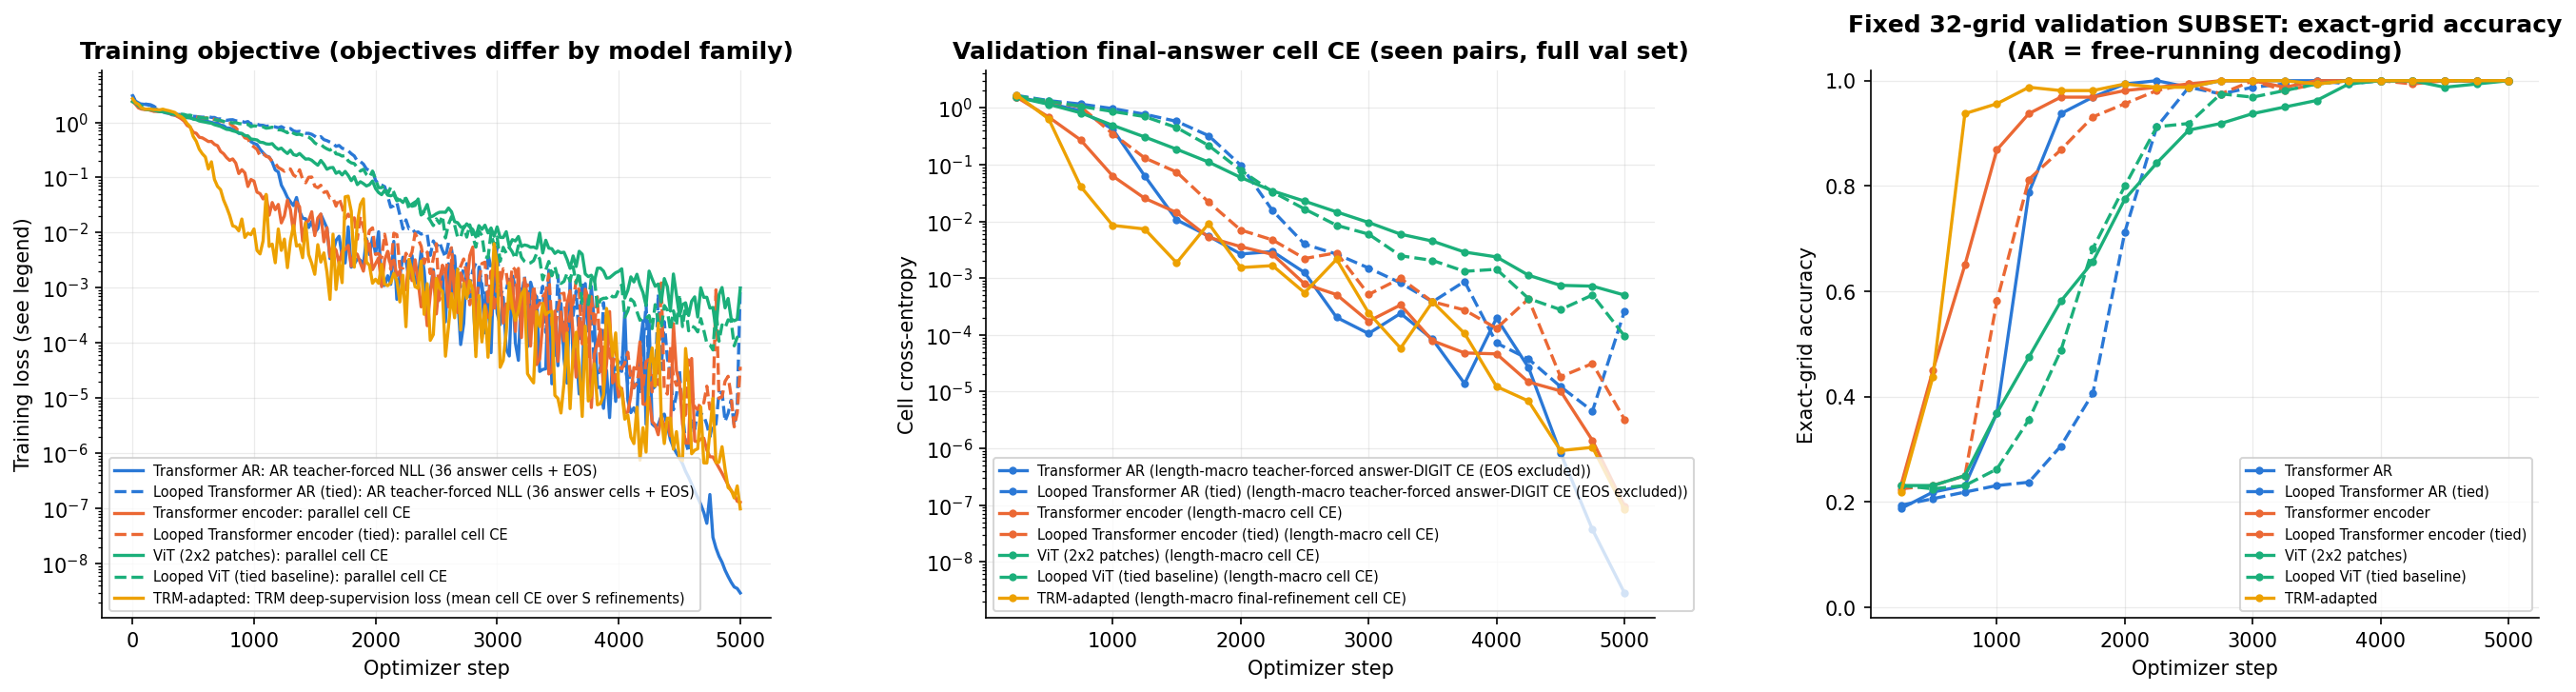

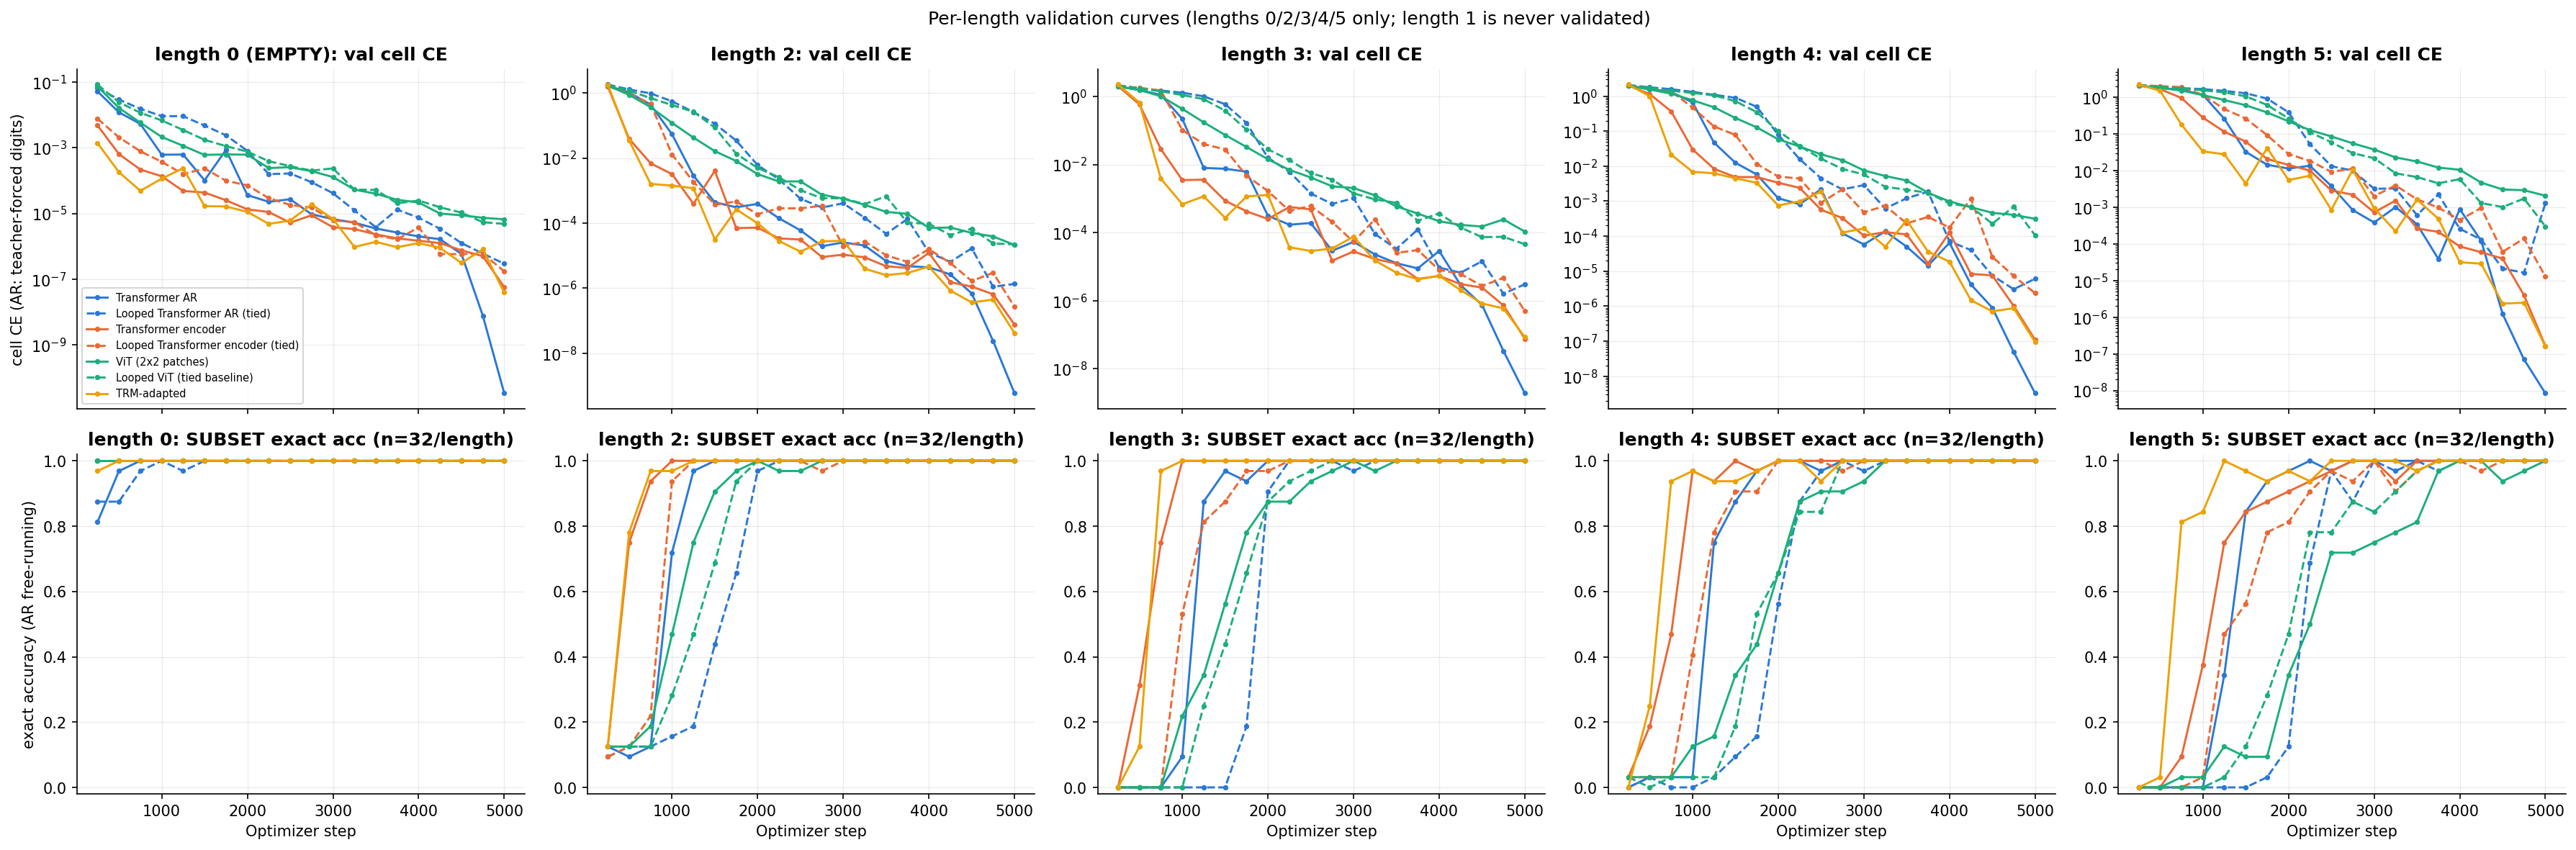

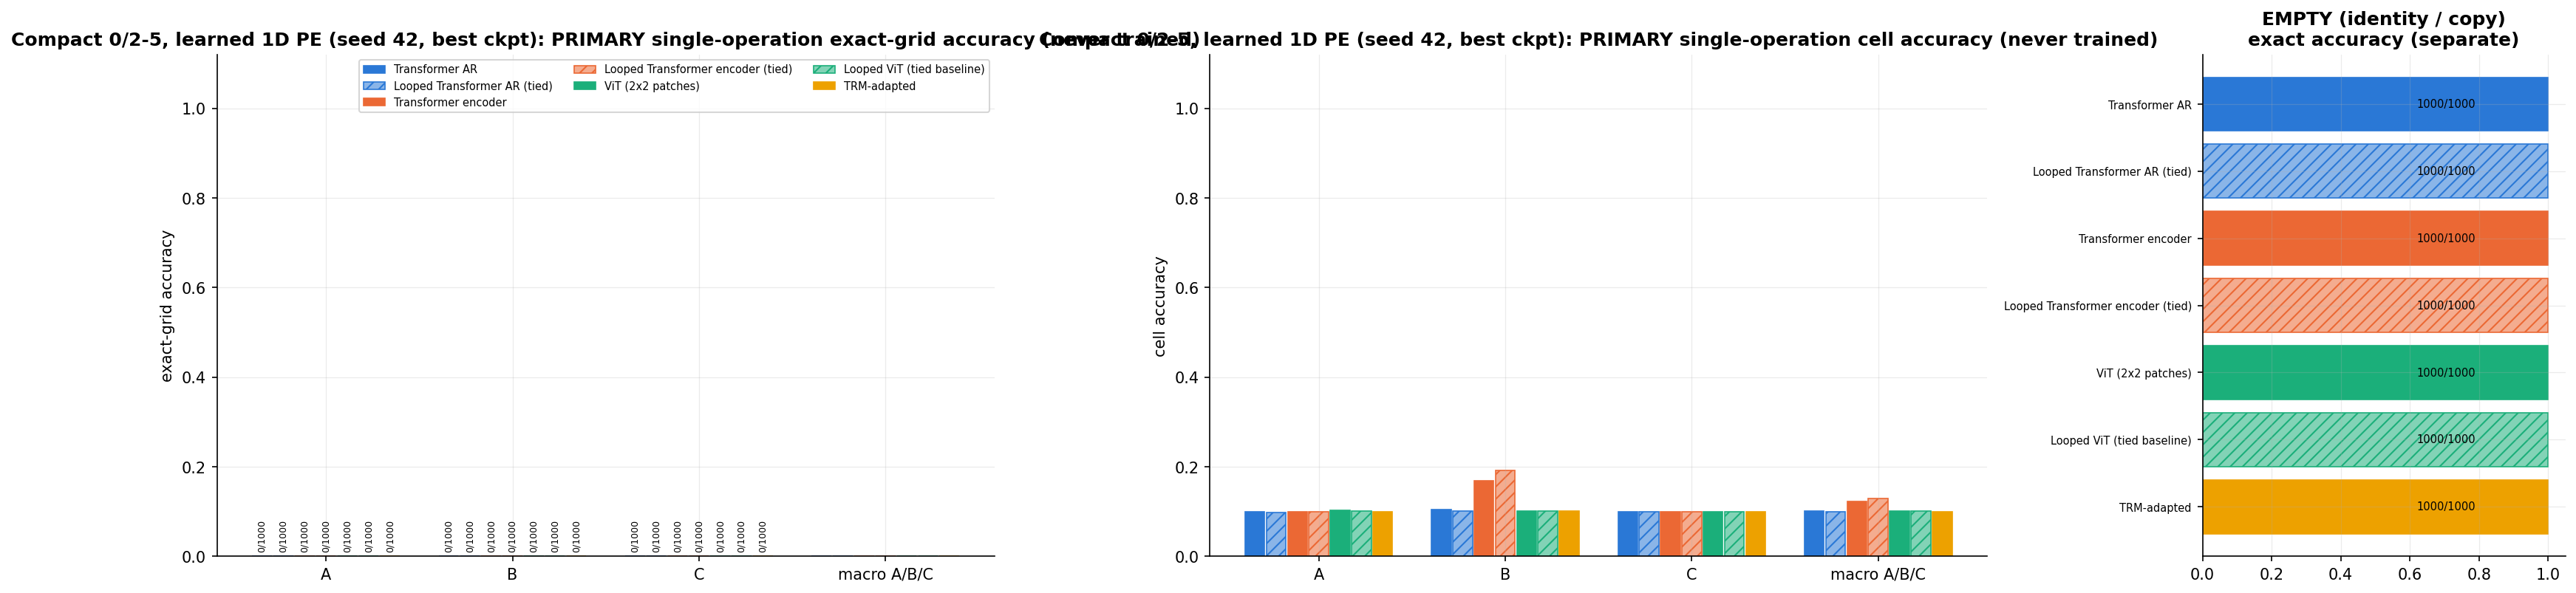

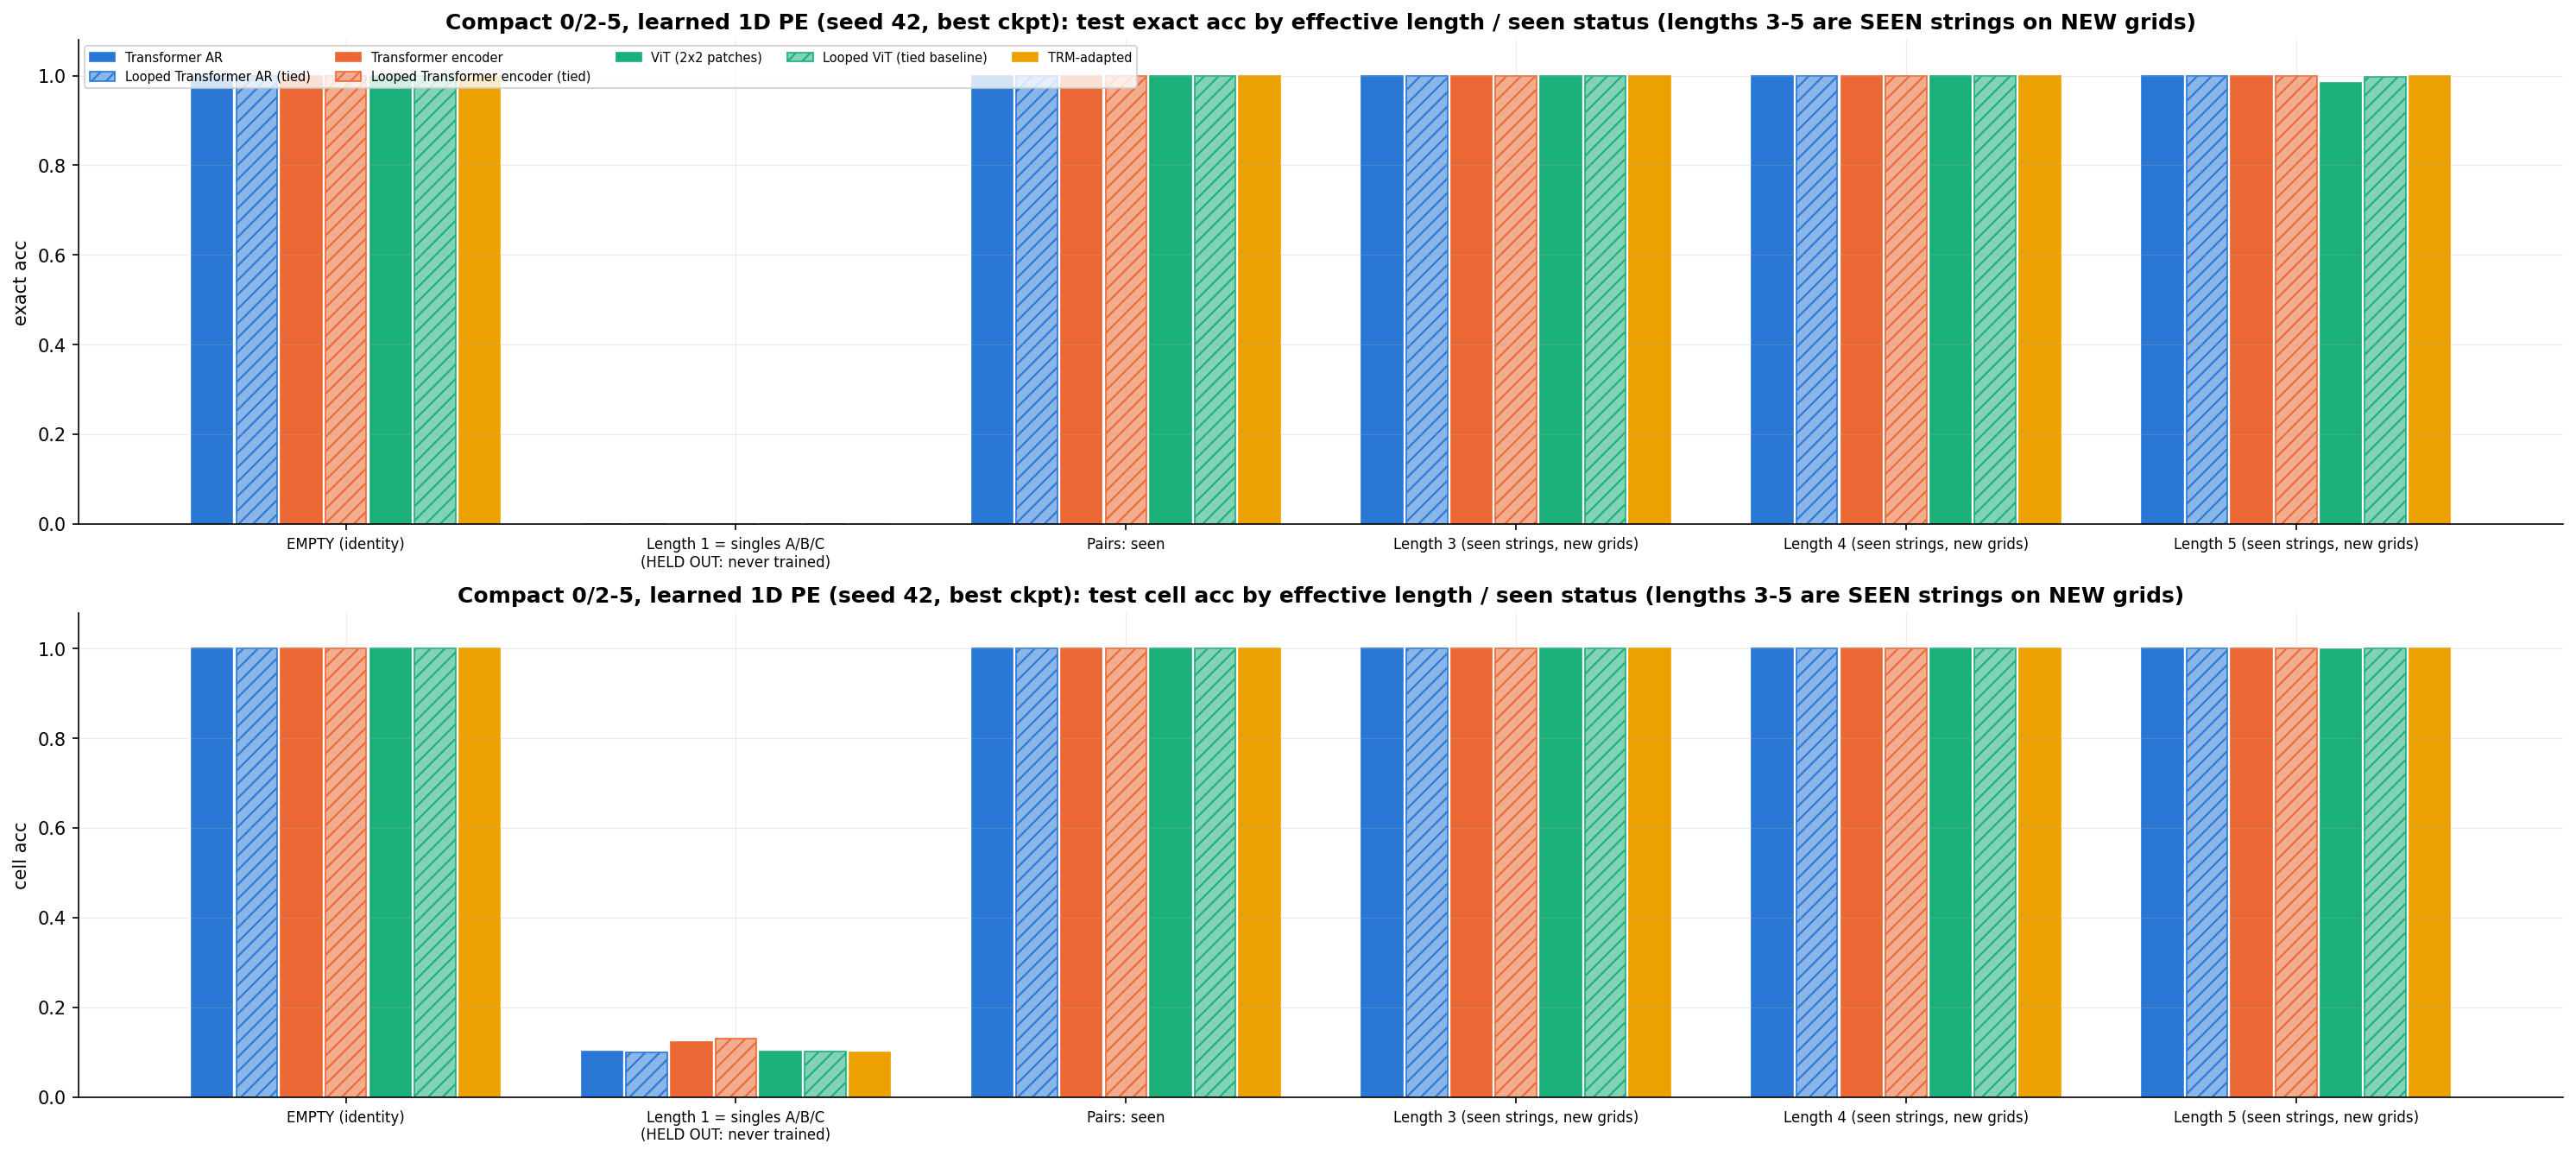

# compact_02345_cnn: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ResCNN-FiLM | 4750 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 27000/27000 | 80995/81000 | 242956/243000 | 0.9916 | 0.8333 | adequate |
| U-Net-FiLM | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000

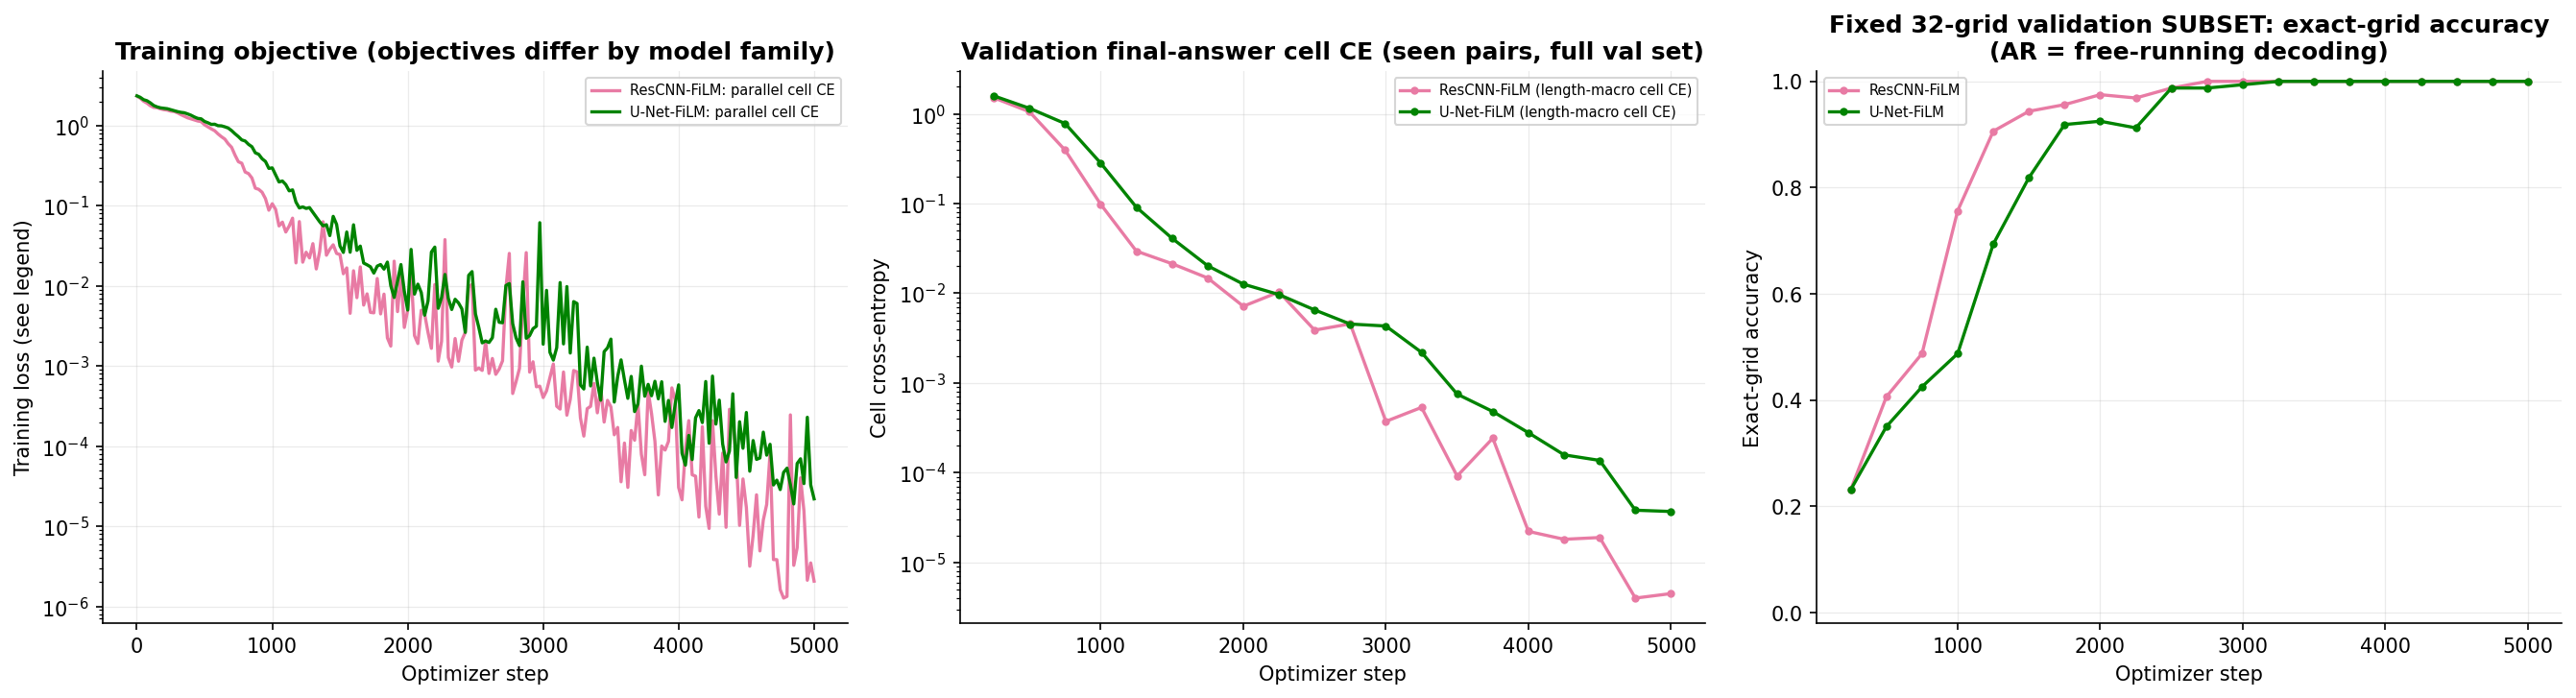

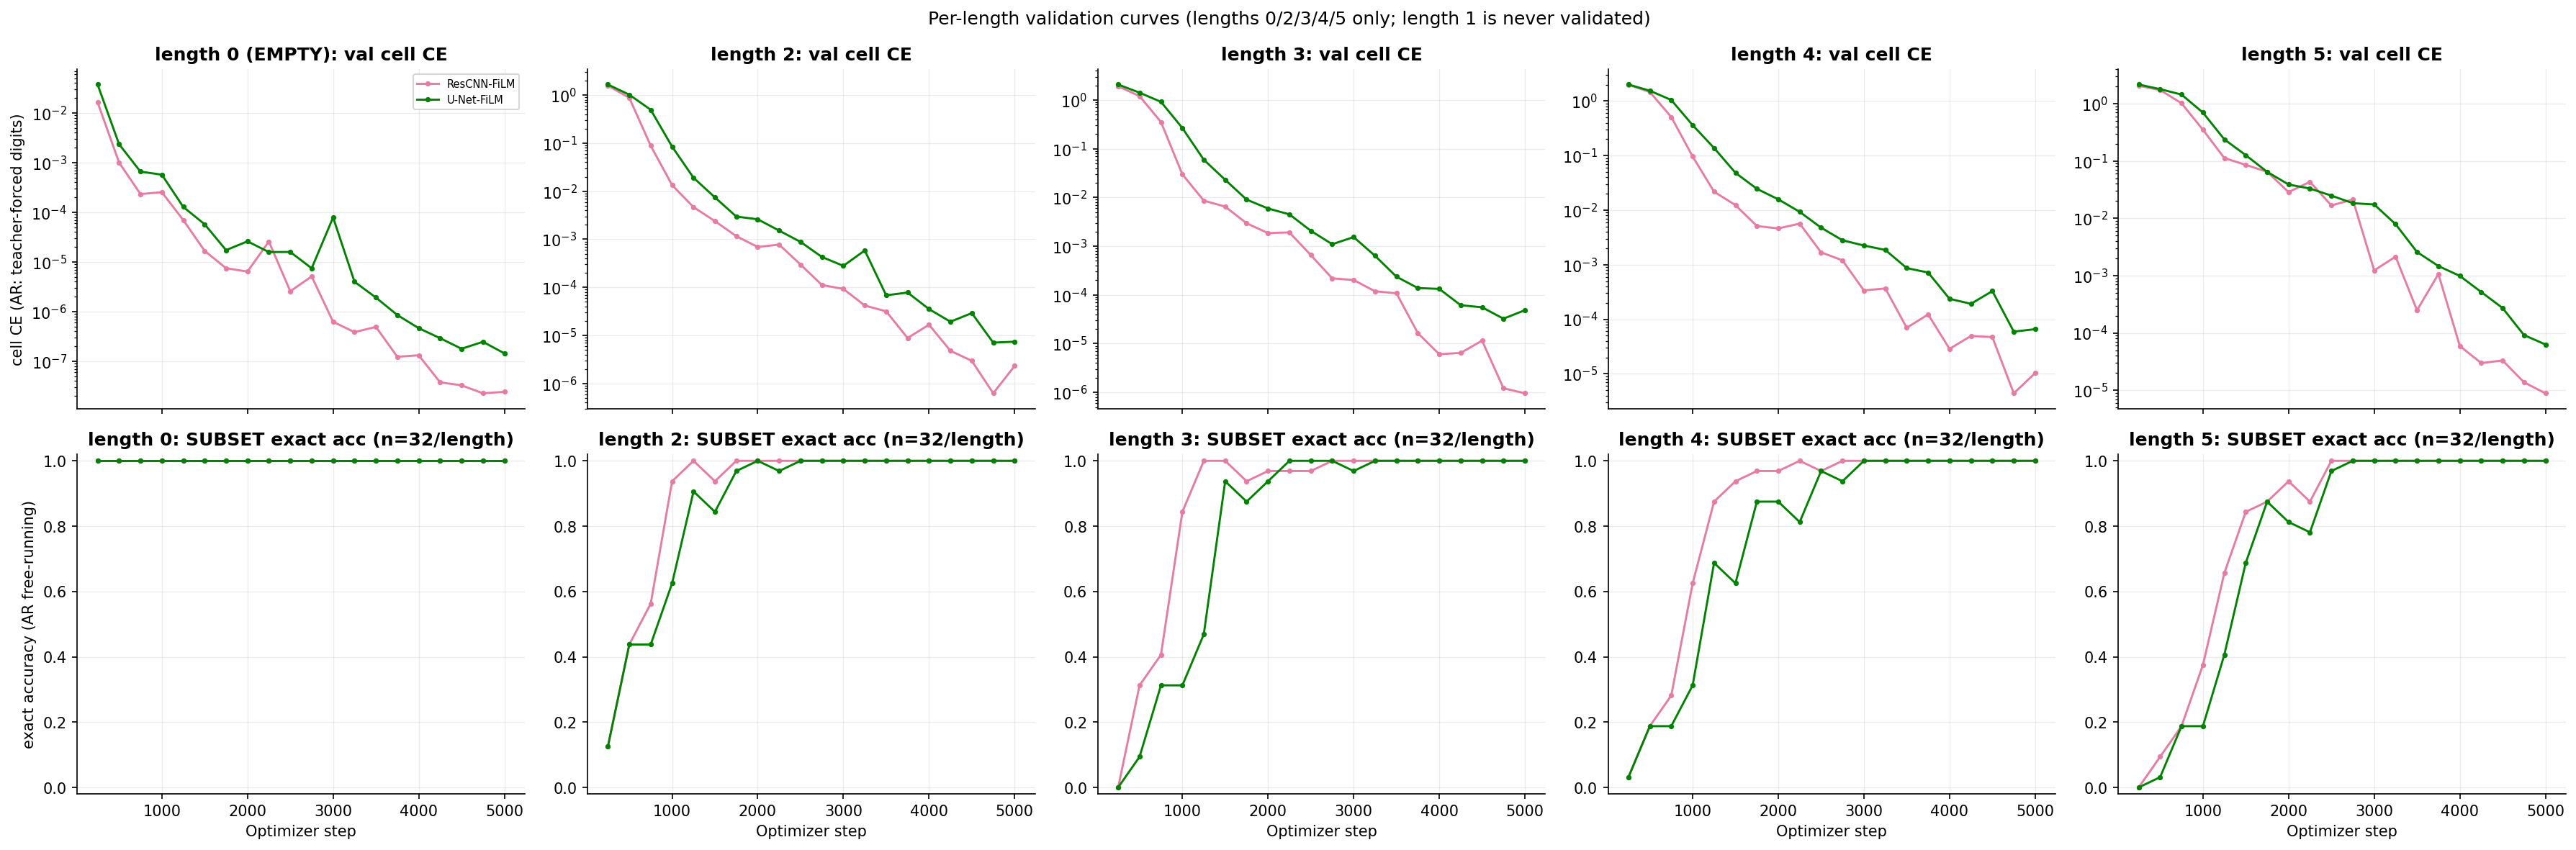

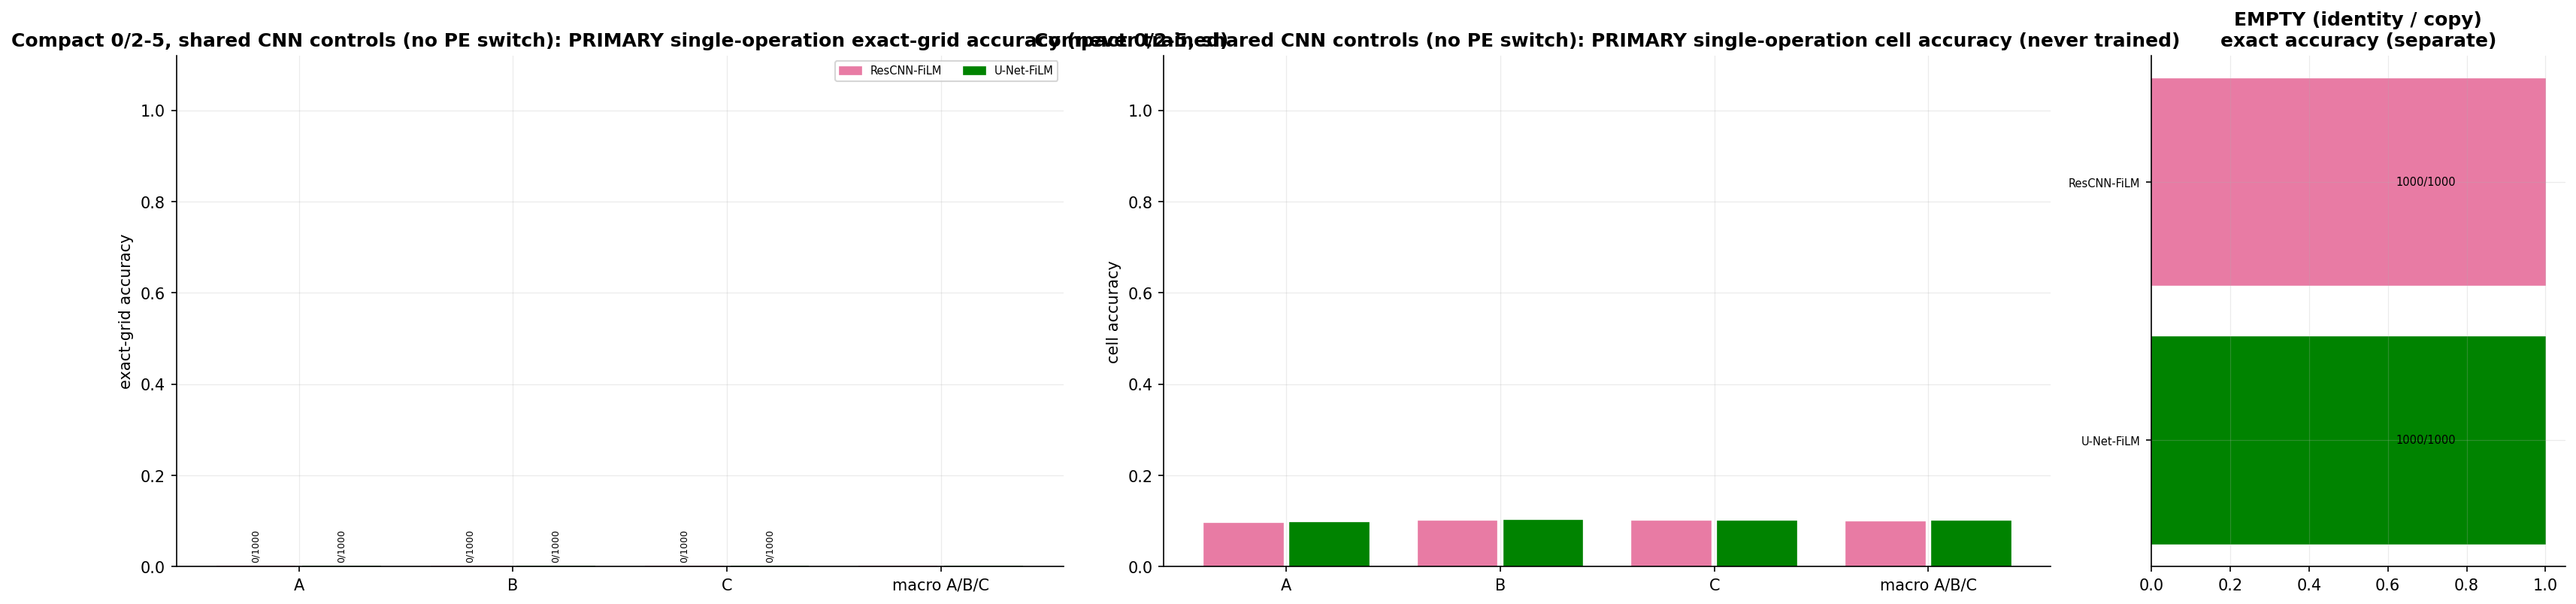

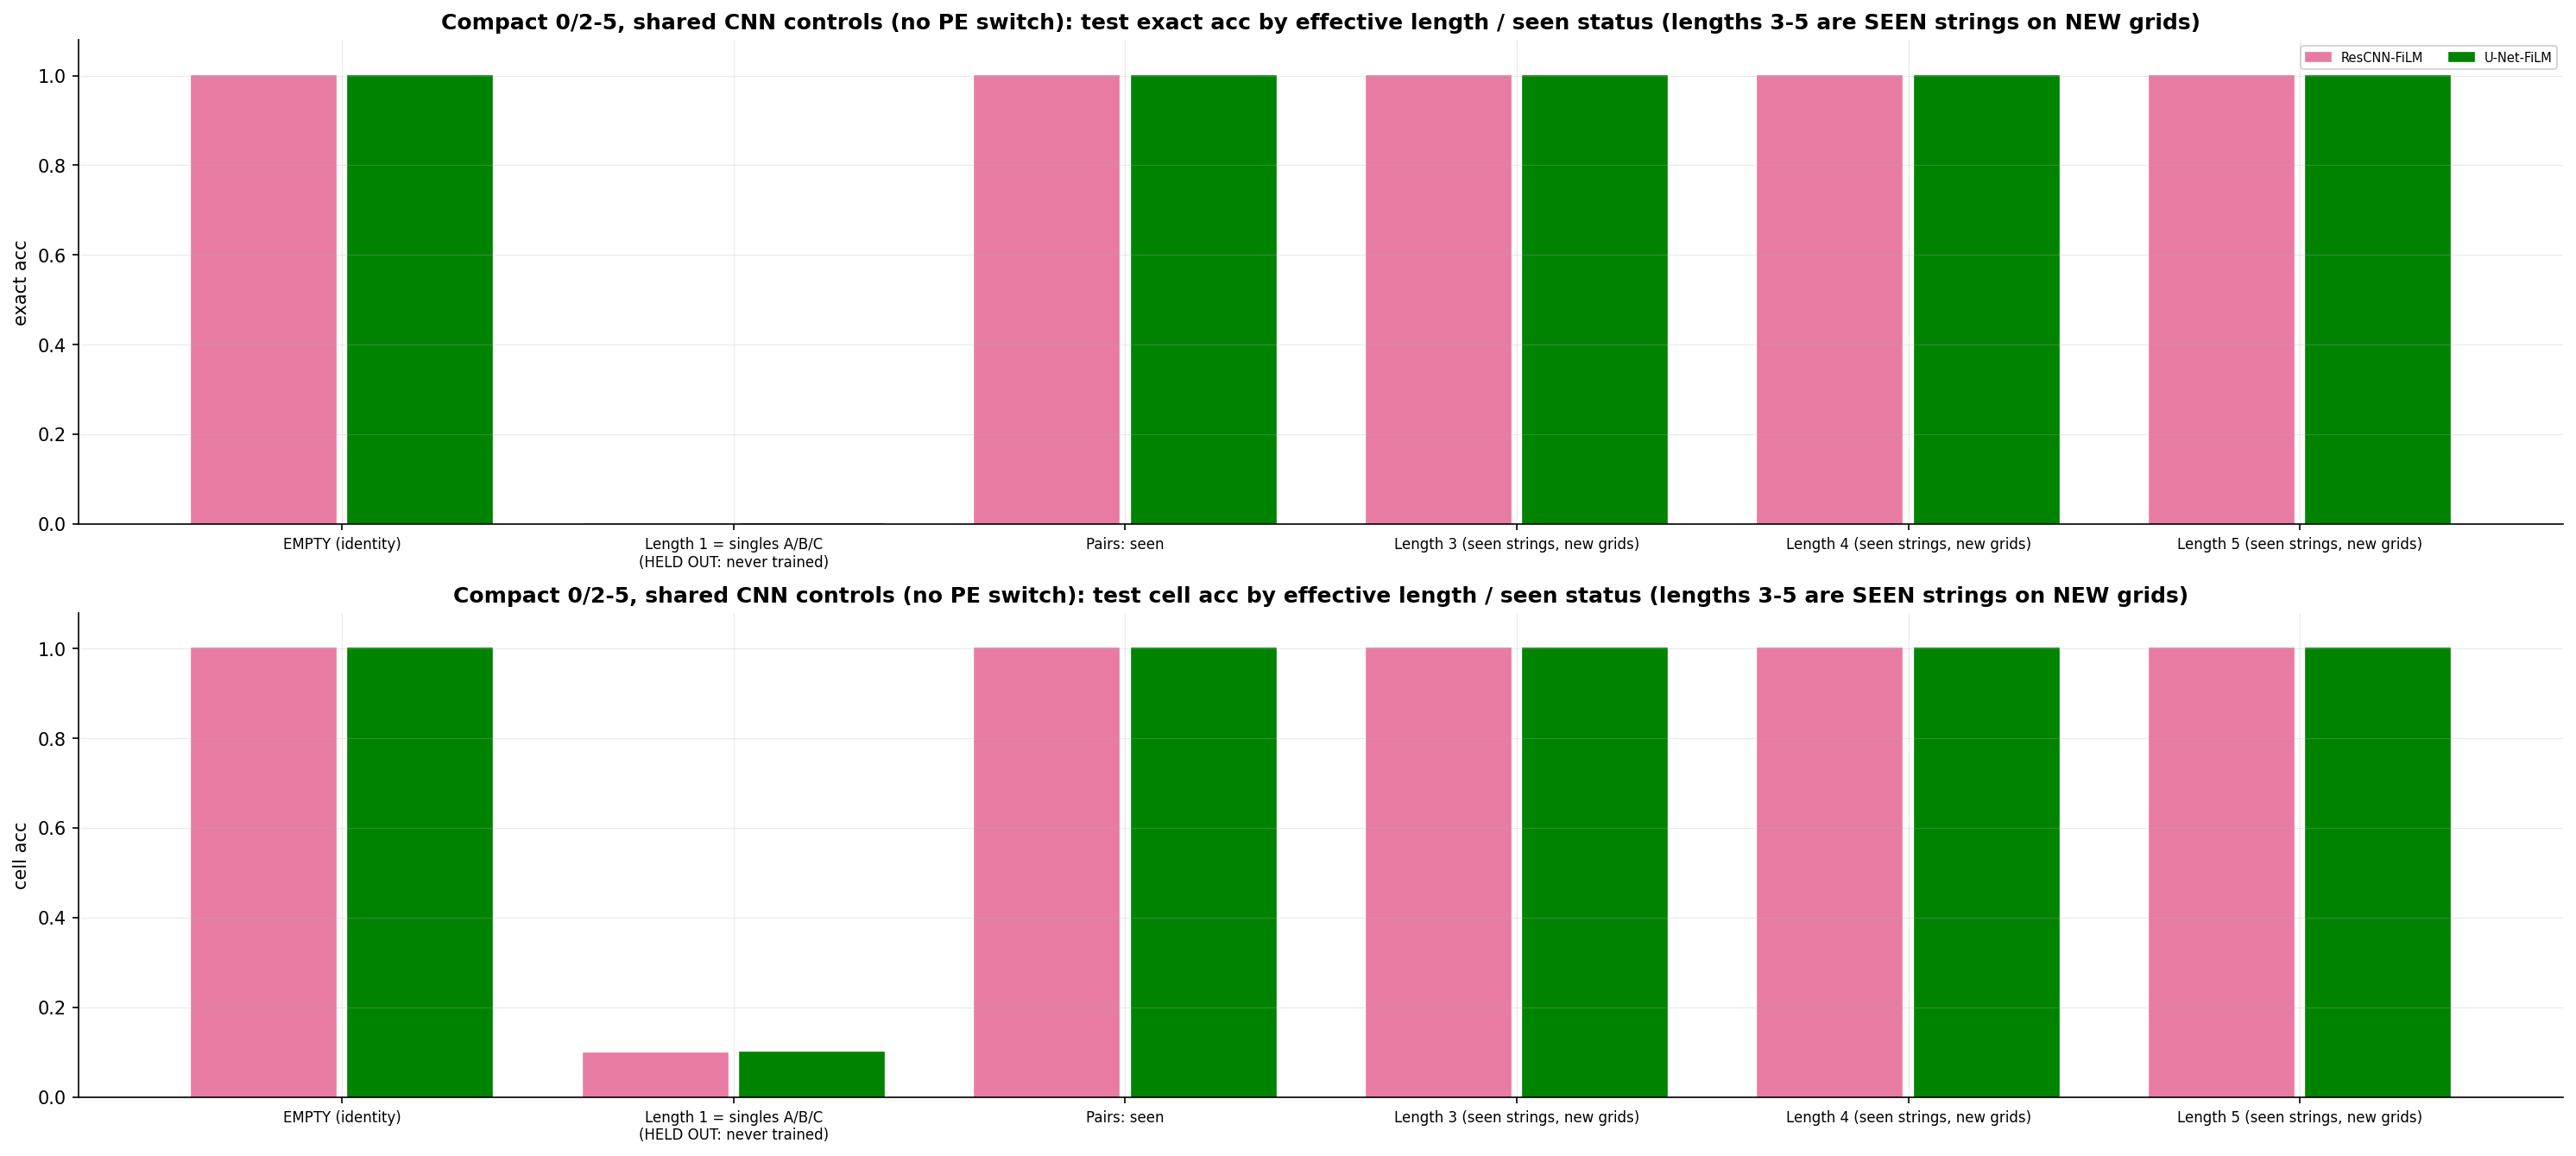

,run,model,condition,status,selected_step,A,B,C,EMPTY,len2,len3,len4,len5,singles_macro_exact
0,rope/transformer_ar,Transformer AR,rope,complete,4500.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26993/27000,80963/81000,242112/243000,0.0
1,rope/looped_transformer_ar,Looped Transformer AR (tied),rope,complete,5000.0,0/1000,0/1000,0/1000,1000/1000,8991/9000,26834/27000,78816/81000,226287/243000,0.0
2,rope/transformer_encoder,Transformer encoder,rope,complete,4500.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26999/27000,80969/81000,242288/243000,0.0
3,rope/looped_transformer_encoder,Looped Transformer encoder (tied),rope,complete,4750.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26999/27000,80959/81000,242626/243000,0.0
4,rope/vit,ViT (2x2 patches),rope,complete,5000.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26996/27000,80931/81000,241635/243000,0.0
5,rope/looped_vit,Looped ViT (tied baseline),rope,complete,5000.0,0/1000,0/1000,0/1000,1000/1000,8997/9000,26945/27000,79642/81000,228903/243000,0.0
6,rope/trm,TRM-adapted,rope,complete,5000.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26997/27000,80985/81000,242762/243000,0.0
7,sinusoidal/transformer_ar,Transformer AR,sinusoidal,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,sinusoidal/looped_transformer_ar,Looped Transformer AR (tied),sinusoidal,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,sinusoidal/transformer_encoder,Transformer encoder,sinusoidal,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# --- Training/evaluation figures and tables ---------------------------------------------------------------------
from decompositionality.mixed_reports import build_mixed_reports
from decompositionality.compact_reports import combined_table
for cfg_ in (cfg_pe, cfg_cnn):
    build_mixed_reports(cfg_.experiment_dir, cfg_.experiment)
    for name in ["a_training_curves", "a2_validation_by_length", "b1_singles_primary_and_empty",
                 "b2_accuracy_by_length_and_seen_status"]:
        p = cfg_.experiment_dir / "figures" / f"{name}.png"
        if p.exists():
            display(Image(filename=str(p)))
FAMILY_ROOT = cfg_pe.experiment_dir.parent      # COMPACT_ROOT (full) or COMPACT_ROOT/smoke (smoke)
display(combined_table(FAMILY_ROOT))


Artifact inventory:
           experiment                      model                           status
compact_02345_learned             transformer_ar predictions available (original)
compact_02345_learned      looped_transformer_ar predictions available (original)
compact_02345_learned        transformer_encoder predictions available (original)
compact_02345_learned looped_transformer_encoder predictions available (original)
compact_02345_learned                        vit predictions available (original)
compact_02345_learned                 looped_vit predictions available (original)
compact_02345_learned                        trm predictions available (original)
    compact_02345_cnn                rescnn_film predictions available (original)
    compact_02345_cnn                  unet_film predictions available (original)
Loaded 9 prediction files; test manifests identical across loaded experiments: True
Synthetic perfect-oracle self-check through the loader/metric path: 364/364 

,experiment,model,string,exact_correct,n,cell_acc,any_exact_group_match_count,dominant_wrong_unique_word,dominant_wrong_unique_share,stable_rule_selected_word,stable_rule_diag_exact_fidelity,argmax_map_diag_cell_fidelity
0,compact_02345_learned,transformer_ar,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
1,compact_02345_learned,transformer_ar,A,0,1000,0.099083,1,AC,0.001,AC,0.002,0.979333
2,compact_02345_learned,transformer_ar,B,0,1000,0.105306,657,BC,0.657,BC,0.634,0.988500
3,compact_02345_learned,transformer_ar,C,0,1000,0.099111,1000,I,1.000,I,1.000,1.000000
40,compact_02345_learned,looped_transformer_ar,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
41,compact_02345_learned,looped_transformer_ar,A,0,1000,0.097750,493,AC,0.493,AC,0.478,0.985667
42,compact_02345_learned,looped_transformer_ar,B,0,1000,0.101806,466,BC,0.466,BC,0.482,0.989167
43,compact_02345_learned,looped_transformer_ar,C,0,1000,0.099111,1000,I,1.000,I,1.000,1.000000
80,compact_02345_learned,transformer_encoder,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
81,compact_02345_learned,transformer_encoder,A,0,1000,0.099028,998,AC,0.998,AC,0.996,0.999889


,experiment,model,population,hypothesis_type,population_records,population_wrong_records,population_any_legal_match_records,applicable_records,eligible_records,matched_unique_records,conditional_rate (matched/eligible),unconditional_coverage (matched/population),truth_equivalent_strings
0,compact_02345_learned,transformer_ar,singletons A/B/C (never trained),identity,3000,3000,1658,3000,3000,1000,0.333333,0.333333,0
1,compact_02345_learned,transformer_ar,singletons A/B/C (never trained),first_op,3000,3000,1658,3000,0,0,NaN,0.000000,3
2,compact_02345_learned,transformer_ar,singletons A/B/C (never trained),last_op,3000,3000,1658,3000,0,0,NaN,0.000000,3
3,compact_02345_learned,transformer_ar,singletons A/B/C (never trained),first_and_last,3000,3000,1658,3000,3000,1000,0.333333,0.333333,0
4,compact_02345_learned,transformer_ar,singletons A/B/C (never trained),first_two,3000,3000,1658,0,0,0,NaN,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
457,compact_02345_cnn,unet_film,singletons A/B/C (never trained),dedupe_global,3000,3000,2118,0,0,0,NaN,0.000000,0
458,compact_02345_cnn,unet_film,singletons A/B/C (never trained),duplicate_single,3000,3000,2118,3000,3000,1000,0.333333,0.333333,0
459,compact_02345_cnn,unet_film,singletons A/B/C (never trained),X_then_C,3000,3000,2118,3000,3000,2118,0.706000,0.706000,0
460,compact_02345_cnn,unet_film,singletons A/B/C (never trained),C_then_X,3000,3000,2118,3000,3000,1000,0.333333,0.333333,0


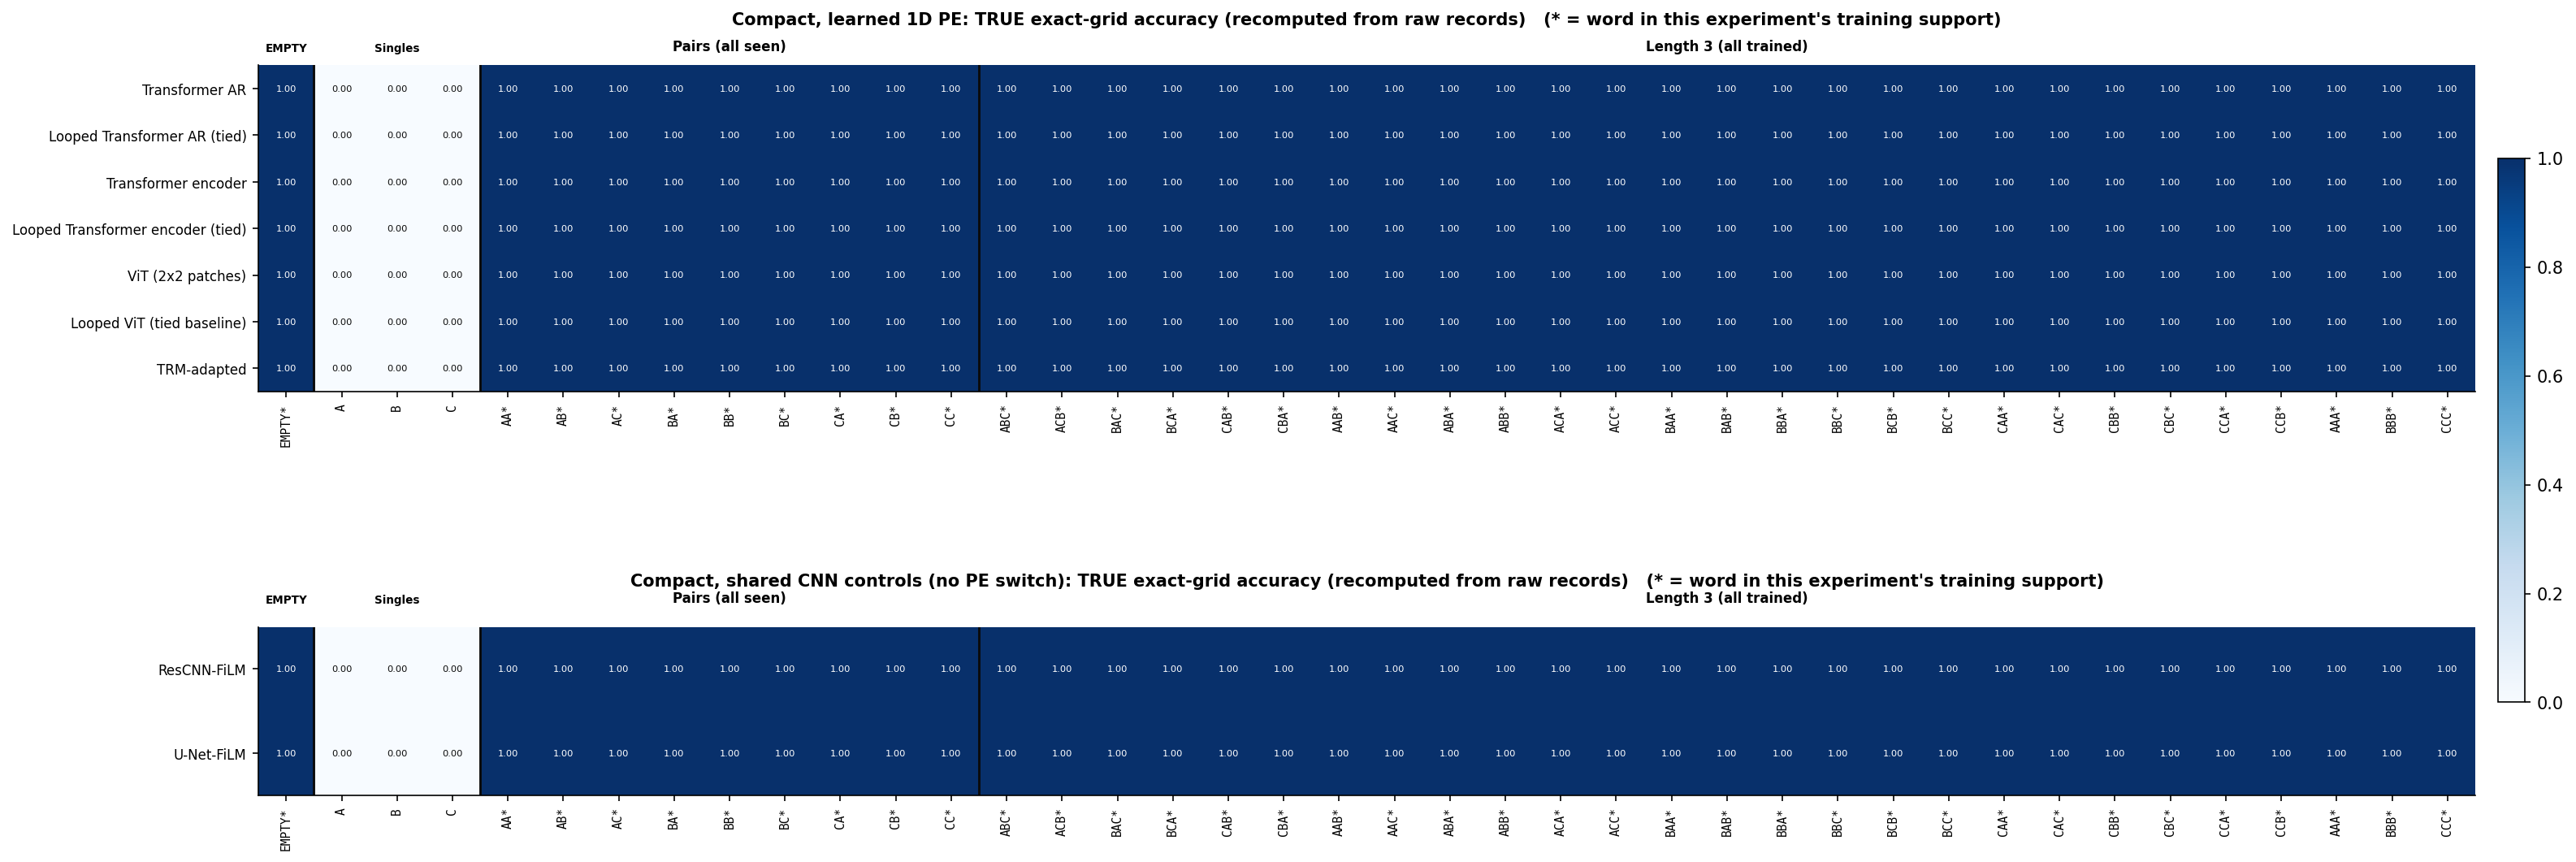

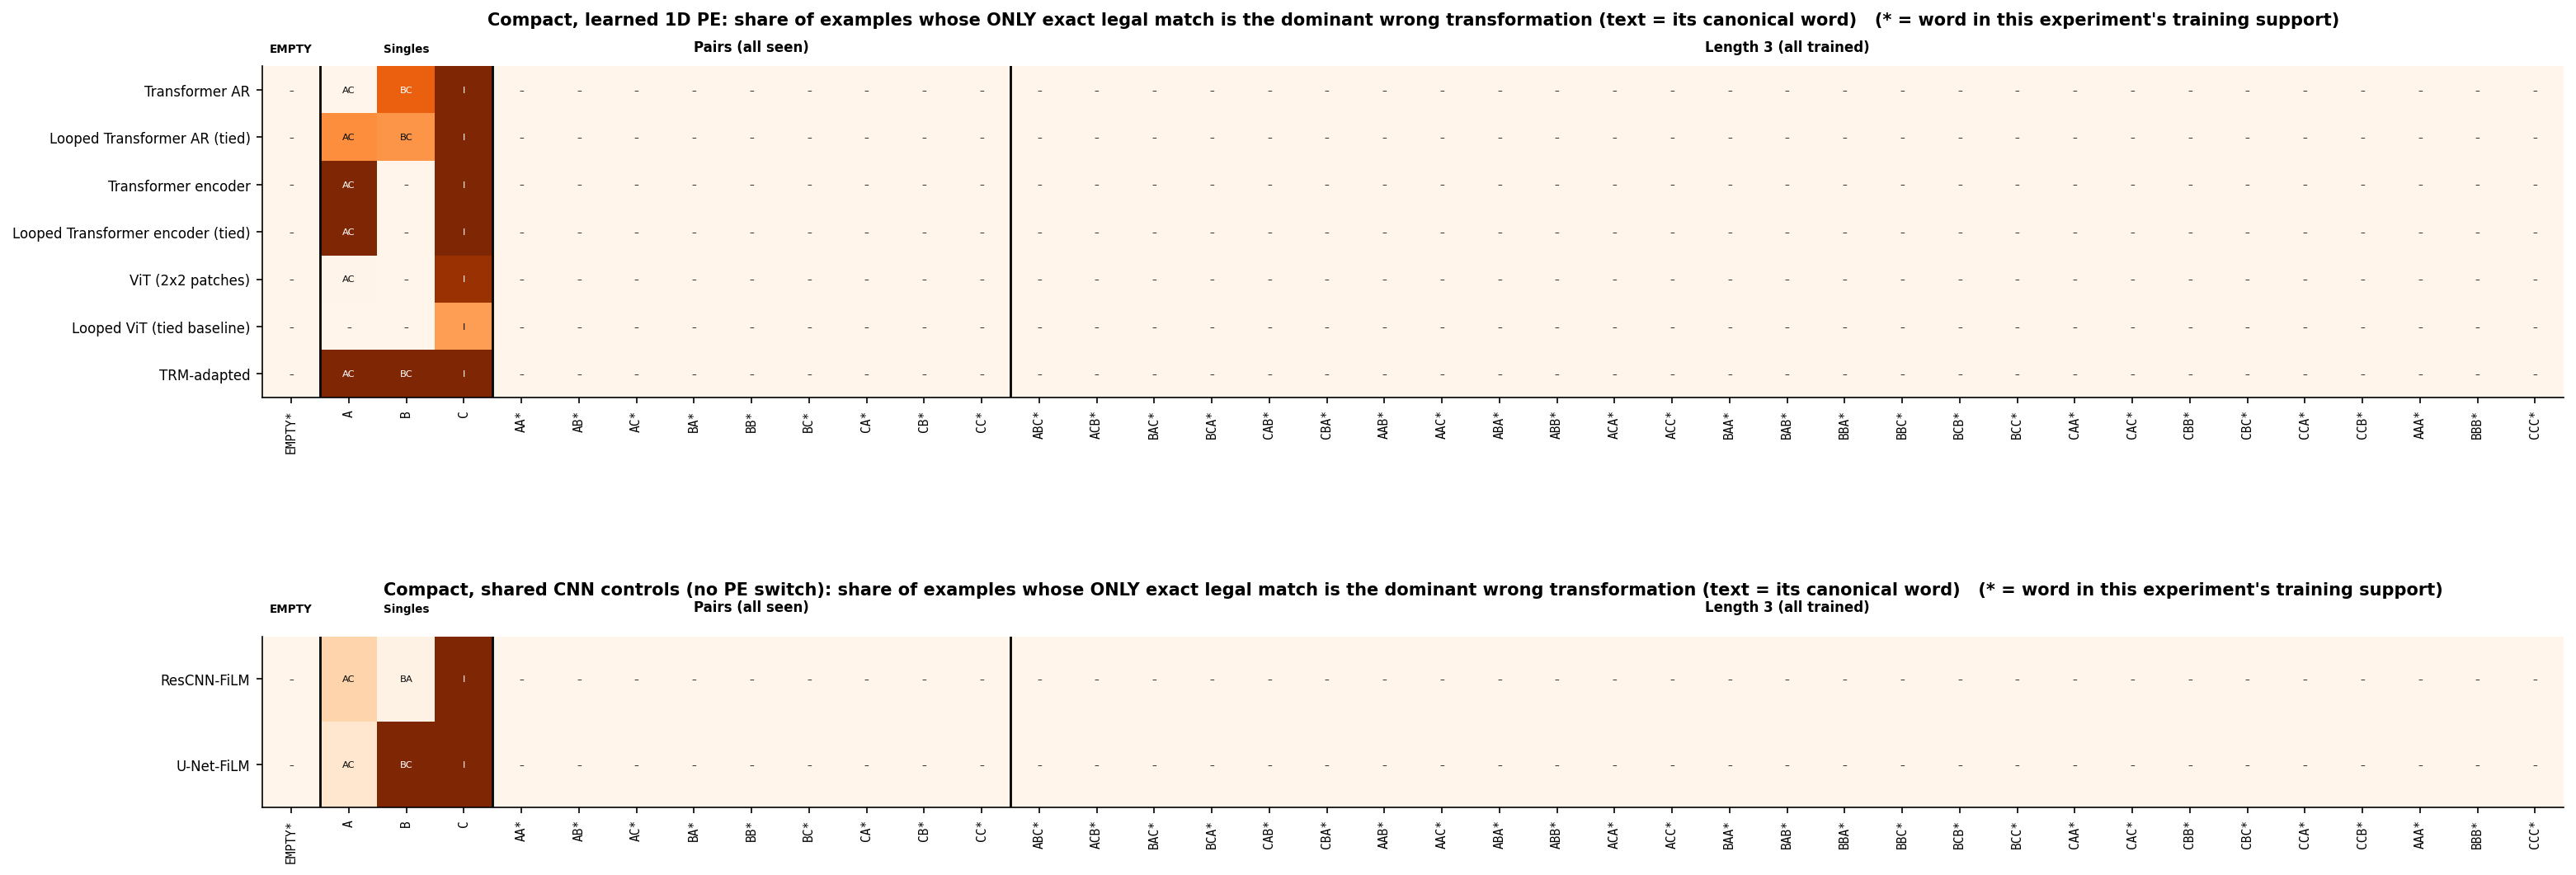

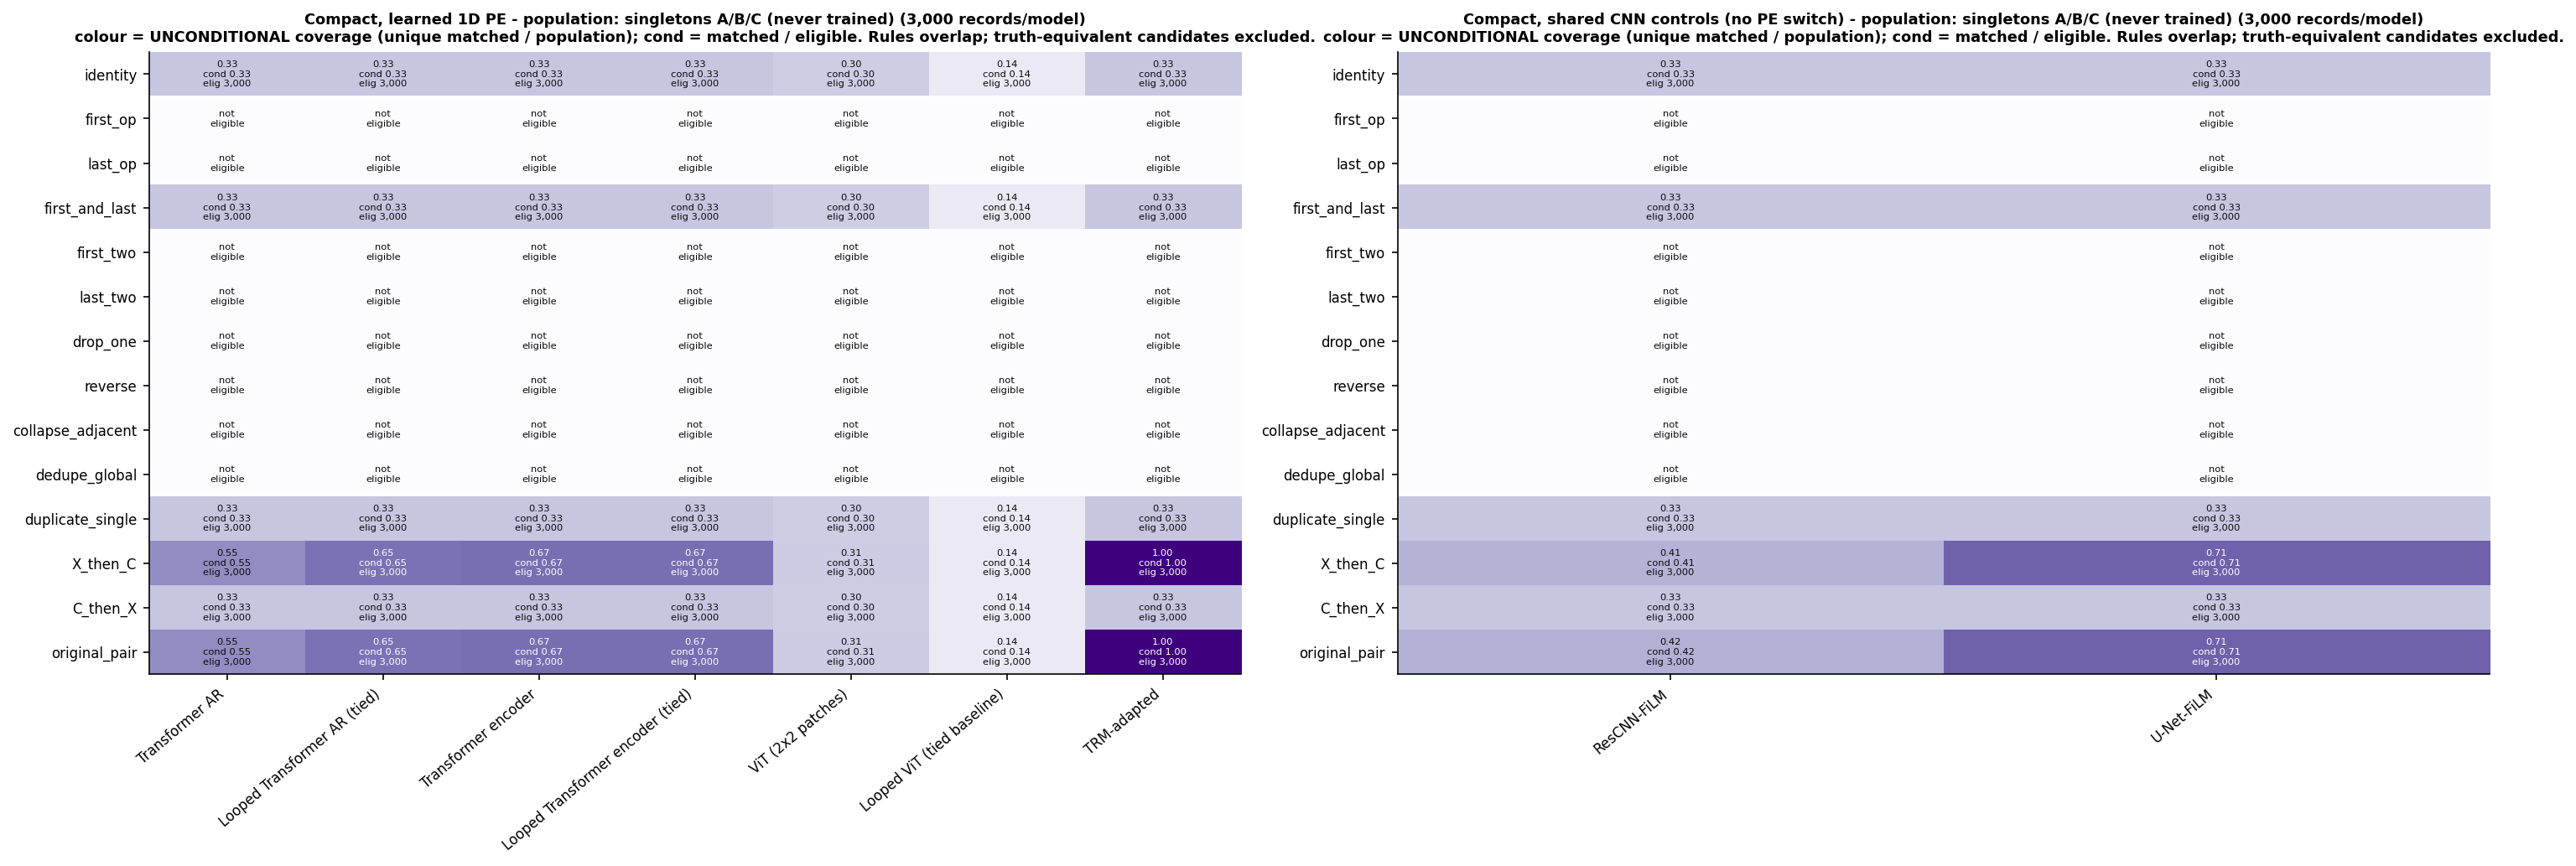

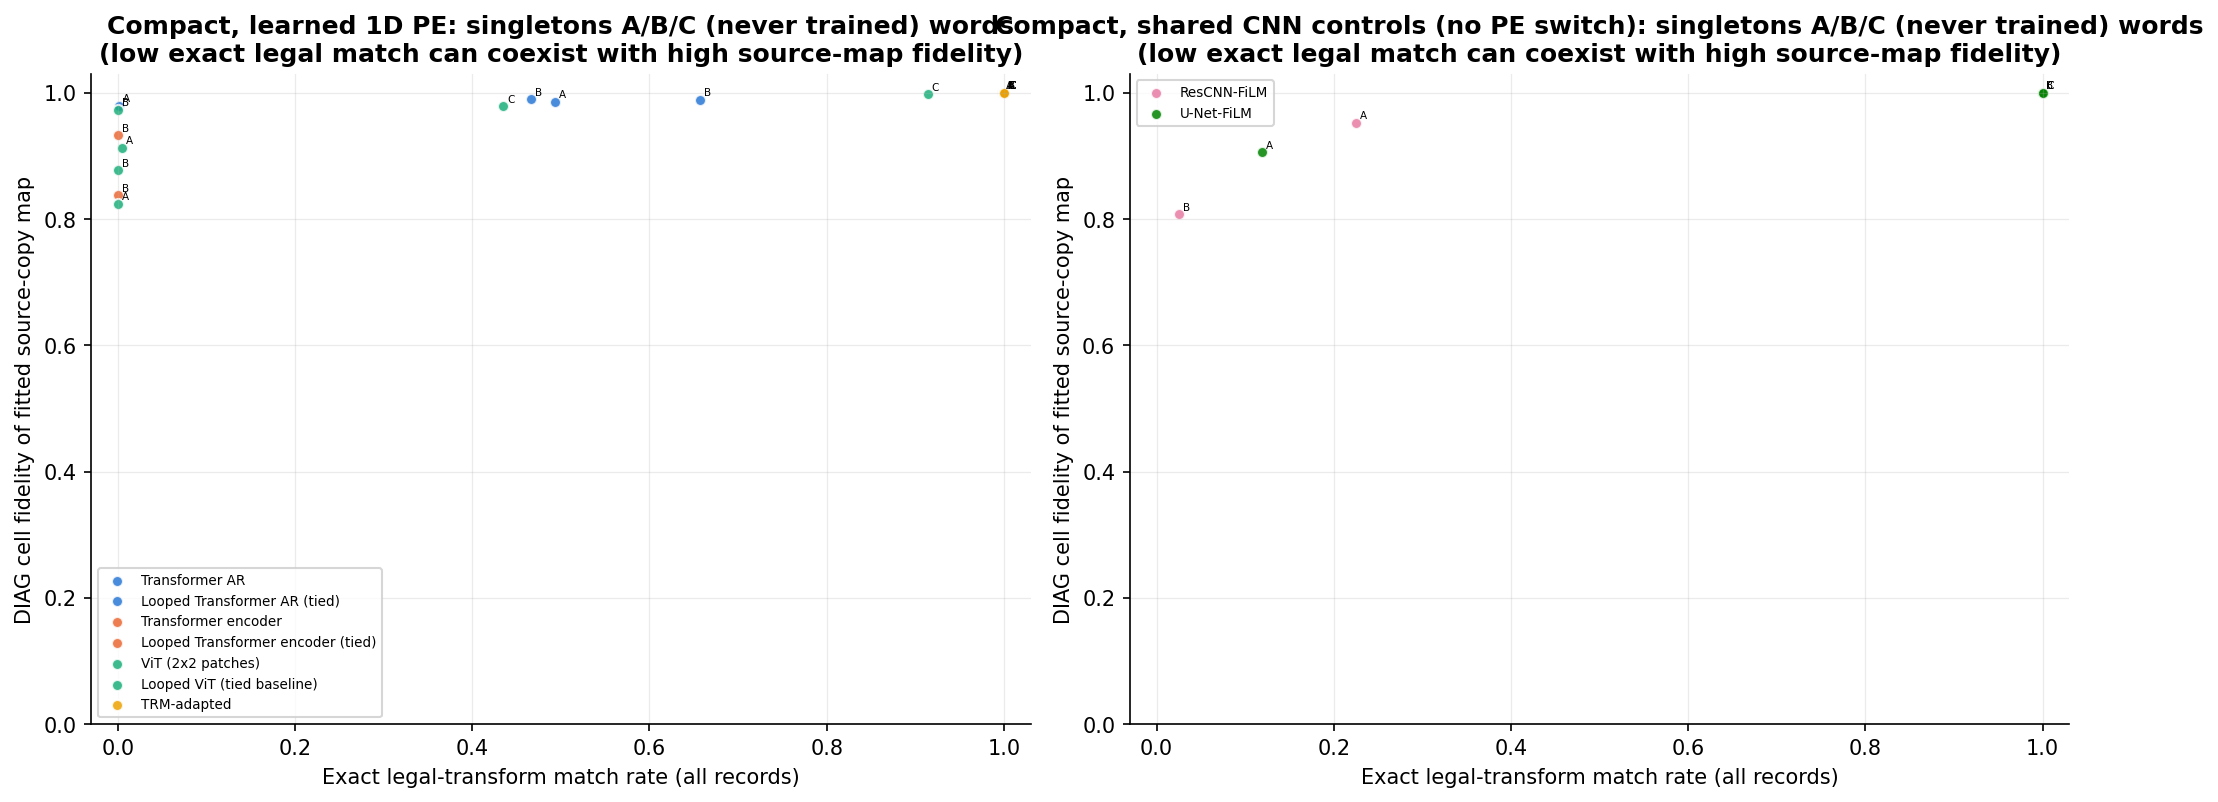

In [9]:
# --- Diagnostics on saved predictions (learned PE + shared CNN controls; read-only) ------------------------------
from decompositionality.diagnosis.runner import DiagnosticsConfig, run_diagnostics
from decompositionality.diagnosis.spec import get_spec
dirs = {cfg_pe.experiment: str(cfg_pe.experiment_dir), cfg_cnn.experiment: str(cfg_cnn.experiment_dir)}
R = run_diagnostics(DiagnosticsConfig(experiment_dirs=dirs, output_dir=str(cfg_pe.experiment_dir / "diagnostics"),
                                      chunk_size=ANALYSIS_CHUNK_SIZE, use_cache=USE_ANALYSIS_CACHE, spec="compact",
                                      analysis_words=get_spec("compact").common_panel,
                                      example_strings=["EMPTY", "A", "B", "C", "AB", "ABC"]))
DFIG = pathlib.Path(R["output_dir"]) / "figures"
def show(prefix):
    for p in sorted(DFIG.glob(prefix + "*.png")):
        display(Image(filename=str(p)))
sing = R["per_string"][R["per_string"].group.isin(["singles", "EMPTY"])]
display(sing[["experiment", "model", "string", "exact_correct", "n", "cell_acc", "any_exact_group_match_count",
              "dominant_wrong_unique_word", "dominant_wrong_unique_share", "stable_rule_selected_word",
              "stable_rule_diag_exact_fidelity", "argmax_map_diag_cell_fidelity"]])
hs = R["hypothesis_summary"]
display(hs[hs.population.str.startswith("singletons")])
show("01_true"); show("04_dominant"); show("05_hypothesis"); show("13_exact")


Paired comparison written to /content/drive/MyDrive/decompositionality_results/compact_02345_pe/comparisons


,model,word_or_group,n,learned_exact,rope_exact,learned_exact_acc,rope_exact_acc,delta_exact (learned - rope),delta_cell (learned - rope),both_correct,only_learned_correct,only_rope_correct,both_wrong,identical_prediction_rate
0,transformer_ar,A,1000,0,0,0.000000,0.000000,0.000000,-0.214194,0,0,0,1000,0.000000
121,transformer_ar,B,1000,0,0,0.000000,0.000000,0.000000,-0.035722,0,0,0,1000,0.000000
242,transformer_ar,C,1000,0,0,0.000000,0.000000,0.000000,0.000000,0,0,0,1000,1.000000
364,transformer_ar,[group] EMPTY,1000,1000,1000,1.000000,1.000000,0.000000,0.000000,1000,0,0,0,1.000000
365,transformer_ar,[group] len3_seen,27000,27000,26993,1.000000,0.999741,0.000259,0.000007,26993,7,0,0,0.999741
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2585,trm,[group] len3_seen,27000,27000,26997,1.000000,0.999889,0.000111,0.000003,26997,3,0,0,0.999889
2586,trm,[group] len4_seen,81000,81000,80985,1.000000,0.999815,0.000185,0.000006,80985,15,0,0,0.999815
2587,trm,[group] len5_seen,243000,242988,242762,0.999951,0.999021,0.000930,0.000039,242750,238,12,0,0.998971
2588,trm,[group] pairs_seen,9000,9000,9000,1.000000,1.000000,0.000000,0.000000,9000,0,0,0,1.000000


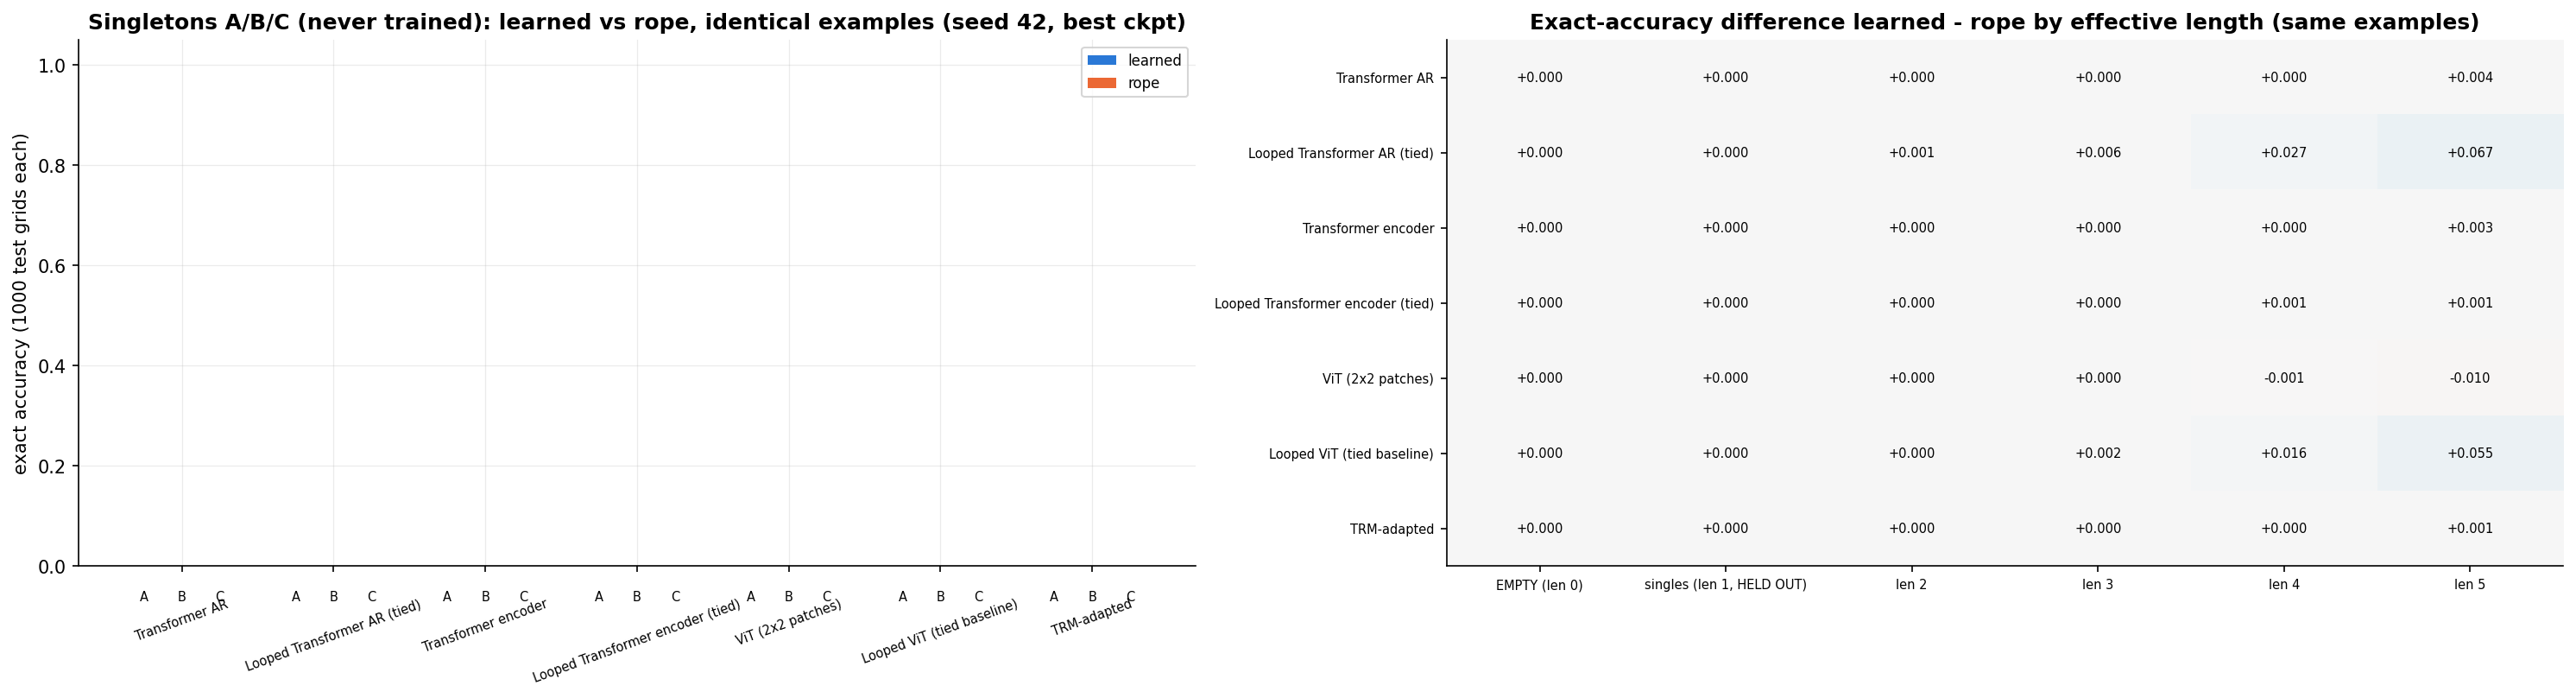

Paired learned-vs-sinusoidal comparison unavailable: both conditions must have completed evaluations (run the other notebook; this notebook does not require it).


In [10]:
# --- Paired comparisons on identical test examples: learned vs RoPE, learned vs sinusoidal (N/A if missing) --------
from decompositionality.compact_reports import paired_pe_comparison
FAMILY_ROOT = cfg_pe.experiment_dir.parent
for other in ("rope", "sinusoidal"):
    pc = paired_pe_comparison(FAMILY_ROOT, a_pe="learned", b_pe=other)
    if pc is not None:
        display(pc[pc.word_or_group.isin(["A", "B", "C"]) | pc.word_or_group.str.startswith("[group]")])
        display(Image(filename=str(FAMILY_ROOT / "comparisons" / f"paired_learned_minus_{other}.png")))


In [11]:
# --- Export (no checkpoints, chunks or caches) --------------------------------------------------------------------
from decompositionality.mixed_reports import make_compact_archive
for cfg_ in (cfg_pe, cfg_cnn):
    make_compact_archive(cfg_.experiment_dir)
display(Markdown(pathlib.Path(R["report_path"]).read_text()))


Compact archive: /content/drive/MyDrive/decompositionality_results/compact_02345_pe/learned/results_learned.zip (28.6 MiB)
Compact archive: /content/drive/MyDrive/decompositionality_results/compact_02345_pe/shared_cnn/results_shared_cnn.zip (6.7 MiB)


# Generalization-failure diagnostics (compact family; analysis generalization-failure-diagnostics-v3)

Generated automatically from the saved prediction artifacts listed below. It describes model BEHAVIOUR on test inputs. Compatibility with an explanation does not establish internal representations or causality; one training seed only.

Definitions: a fitted fixed rule is **stable** if its DIAG exact fidelity >= 0.95; a source map is **adequate** if its DIAG cell fidelity >= 0.9. DIAG = disjoint half of the base grids not used for fitting.

## 1. Data coverage and provenance

| experiment | model | status |
|---|---|---|
| compact_02345_learned | transformer_ar | predictions available (original) |
| compact_02345_learned | looped_transformer_ar | predictions available (original) |
| compact_02345_learned | transformer_encoder | predictions available (original) |
| compact_02345_learned | looped_transformer_encoder | predictions available (original) |
| compact_02345_learned | vit | predictions available (original) |
| compact_02345_learned | looped_vit | predictions available (original) |
| compact_02345_learned | trm | predictions available (original) |
| compact_02345_cnn | rescnn_film | predictions available (original) |
| compact_02345_cnn | unet_film | predictions available (original) |

### Audit

| experiment | model | source | n_records | n_strings | selected_step | code_commit_at_eval | decoding | duplicate_keys | invalid_records | target_oracle_mismatches | input_manifest_mismatches | attribution_blocked |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| compact_02345_learned | transformer_ar | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | looped_transformer_ar | original | 364000 | 364 | 4750 | a148085c7359ba06c019910a01c67a6b033a95ed | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | transformer_encoder | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | looped_transformer_encoder | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | vit | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | looped_vit | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_learned | trm | original | 364000 | 364 | 5000 | a148085c7359ba06c019910a01c67a6b033a95ed | parallel prediction (parallel argmax of final refinement); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_cnn | rescnn_film | original | 364000 | 364 | 4750 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_cnn | unet_film | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |


- Stored targets re-derived with the independent oracle for **3,276,000** records; mismatches: **0**.
- Test manifests identical across loaded experiments: **True**.
- A synthetic perfect-oracle predictor passed through the same loader/metric code scores 100% on all 364 words (checks the analysis path, not any checkpoint's forward pass).

## 2. Verified observations (recomputed from raw records)

Integer exact successes / records are shown; rates have 4 decimals (e.g. 8998/9000 = 0.9998 is NOT 1). Columns prefixed DIAG use only the diagnostic half of the base grids. N/A = empty category.

| experiment | model | group | exact_correct | n_records | true_exact_acc | true_cell_acc | any_legal_match_records | any_exact_legal_match | exact_set_includes_original_pair | DIAG stable_rule_exact_fidelity | DIAG argmax_map_cell_fidelity | DIAG bijective_perm_cell_fidelity |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| compact_02345_learned | Transformer AR | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer AR | singles | 0 | 3000 | 0.0000 | 0.1012 | 1658 | 0.5527 | 0.5527 | 0.5453 | 0.9893 | 0.9671 |
| compact_02345_learned | Transformer AR | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer AR | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer AR | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Transformer AR | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped Transformer AR (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer AR (tied) | singles | 0 | 3000 | 0.0000 | 0.0996 | 1959 | 0.6530 | 0.6530 | 0.6533 | 0.9916 | 0.9898 |
| compact_02345_learned | Looped Transformer AR (tied) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer AR (tied) | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer AR (tied) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped Transformer AR (tied) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Transformer encoder | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer encoder | singles | 0 | 3000 | 0.0000 | 0.1222 | 1998 | 0.6660 | 0.6660 | 0.6653 | 0.9774 | 0.9433 |
| compact_02345_learned | Transformer encoder | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer encoder | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Transformer encoder | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Transformer encoder | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped Transformer encoder (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.0000 | 0.1297 | 1999 | 0.6663 | 0.6663 | 0.6667 | 0.9459 | 0.8973 |
| compact_02345_learned | Looped Transformer encoder (tied) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer encoder (tied) | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped Transformer encoder (tied) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped Transformer encoder (tied) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | ViT (2x2 patches) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | ViT (2x2 patches) | singles | 0 | 3000 | 0.0000 | 0.1012 | 919 | 0.3063 | 0.3063 | 0.3067 | 0.9292 | 0.9058 |
| compact_02345_learned | ViT (2x2 patches) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | ViT (2x2 patches) | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | ViT (2x2 patches) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | ViT (2x2 patches) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped ViT (tied baseline) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.0000 | 0.1005 | 435 | 0.1450 | 0.1450 | 0.1420 | 0.9250 | 0.8529 |
| compact_02345_learned | Looped ViT (tied baseline) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped ViT (tied baseline) | len3_seen | 26997 | 27000 | 0.9999 | 1.0000 | 26997 | 0.9999 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_learned | Looped ViT (tied baseline) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | Looped ViT (tied baseline) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | TRM-adapted | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | TRM-adapted | singles | 0 | 3000 | 0.0000 | 0.0999 | 3000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | TRM-adapted | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | TRM-adapted | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_learned | TRM-adapted | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_learned | TRM-adapted | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | ResCNN-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | singles | 0 | 3000 | 0.0000 | 0.0979 | 1250 | 0.4167 | 0.4167 | 0.4200 | 0.9198 | 0.9197 |
| compact_02345_cnn | ResCNN-FiLM | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | ResCNN-FiLM | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | U-Net-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | singles | 0 | 3000 | 0.0000 | 0.0990 | 2118 | 0.7060 | 0.7060 | 0.7020 | 0.9686 | 0.9686 |
| compact_02345_cnn | U-Net-FiLM | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | U-Net-FiLM | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |


### compact_02345_learned - population 'singletons A/B/C (never trained)'

- Exact-correct: 0 of 21,000 records (0.000000).
- Wrong predictions exactly equal to SOME legal transform of the input: 11,968 of 21,000 wrong records (0.5699).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 11,968 of 21,000.
- (model, word) cells with a STABLE fitted fixed rule: 9 of 21 (of which the rule is the truth in 0, an original pair transformation in 9, the Z-twisted alternative in 0).
  - most frequent stable WRONG rules (canonical words): I x5, AC x3, BC x1
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.0638, with true targets 0.0638; 116 of 252 rows WEAK (unstable single maps).

### compact_02345_cnn - population 'singletons A/B/C (never trained)'

- Exact-correct: 0 of 6,000 records (0.000000).
- Wrong predictions exactly equal to SOME legal transform of the input: 3,368 of 6,000 wrong records (0.5613).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 3,368 of 6,000.
- (model, word) cells with a STABLE fitted fixed rule: 3 of 6 (of which the rule is the truth in 0, an original pair transformation in 3, the Z-twisted alternative in 0).
  - most frequent stable WRONG rules (canonical words): I x2, BC x1
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.0694, with true targets 0.0694; 24 of 72 rows WEAK (unstable single maps).

### Hypothesis coverage with explicit denominators (population: singletons A/B/C (never trained))

matched = UNIQUE records matched by ANY non-truth candidate of the rule (union within the rule; rules overlap with each other). conditional = matched / eligible; unconditional = matched / population. any-legal = records exactly equal to some legal transform (an upper bound for unconditional coverage).

(summed over models)

| experiment | hypothesis_type | population | any_legal | eligible | matched | conditional | unconditional |
|---|---|---|---|---|---|---|---|
| compact_02345_learned | identity | 21000 | 11968 | 21000 | 6349 | 0.3023 | 0.3023 |
| compact_02345_learned | first_op | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | last_op | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | first_and_last | 21000 | 11968 | 21000 | 6349 | 0.3023 | 0.3023 |
| compact_02345_learned | first_two | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | last_two | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | drop_one | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | reverse | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | collapse_adjacent | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | dedupe_global | 21000 | 11968 | 0 | 0 | N/A | 0.0000 |
| compact_02345_learned | duplicate_single | 21000 | 11968 | 21000 | 6349 | 0.3023 | 0.3023 |
| compact_02345_learned | X_then_C | 21000 | 11968 | 21000 | 11968 | 0.5699 | 0.5699 |
| compact_02345_learned | C_then_X | 21000 | 11968 | 21000 | 6349 | 0.3023 | 0.3023 |
| compact_02345_learned | original_pair | 21000 | 11968 | 21000 | 11968 | 0.5699 | 0.5699 |
| compact_02345_cnn | identity | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | first_op | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | last_op | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | first_and_last | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | first_two | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | last_two | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | drop_one | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | reverse | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | collapse_adjacent | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | dedupe_global | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | duplicate_single | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | X_then_C | 6000 | 3368 | 6000 | 3344 | 0.5573 | 0.5573 |
| compact_02345_cnn | C_then_X | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | original_pair | 6000 | 3368 | 6000 | 3368 | 0.5613 | 0.5613 |


## 3. Hypotheses compatible with the observations (behavioural, non-causal)

- compact_02345_learned: rule 'original_pair' exactly matches 11,968 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5699; conditional 0.5699 of 21,000 eligible).
- compact_02345_learned: rule 'X_then_C' exactly matches 11,968 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5699; conditional 0.5699 of 21,000 eligible).
- compact_02345_learned: rule 'C_then_X' exactly matches 6,349 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3023; conditional 0.3023 of 21,000 eligible).
- compact_02345_learned: rule 'duplicate_single' exactly matches 6,349 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3023; conditional 0.3023 of 21,000 eligible).
- compact_02345_learned: rule 'identity' exactly matches 6,349 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3023; conditional 0.3023 of 21,000 eligible).
- compact_02345_learned: rule 'first_and_last' exactly matches 6,349 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3023; conditional 0.3023 of 21,000 eligible).
- compact_02345_cnn: rule 'original_pair' exactly matches 3,368 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5613; conditional 0.5613 of 6,000 eligible).
- compact_02345_cnn: rule 'X_then_C' exactly matches 3,344 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5573; conditional 0.5573 of 6,000 eligible).
- compact_02345_cnn: rule 'identity' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'C_then_X' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'first_and_last' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'duplicate_single' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).

## 4. Unresolved cases

(model, word) cells in 'singletons A/B/C (never trained)' that are mostly wrong (exact < 0.5) with no stable legal rule (DIAG exact < 0.5) AND no adequate source map (DIAG cell fidelity < 0.9): **4**. This only rules out these explanation families; it is not evidence of randomness.

| experiment | model | string |
|---|---|---|
| compact_02345_cnn | rescnn_film | B |
| compact_02345_learned | looped_transformer_encoder | B |
| compact_02345_learned | looped_vit | A |
| compact_02345_learned | vit | B |


## 5. Limits

- Matching one of the 288 transformations does not identify which synonymous string was executed; ambiguous matches are kept ambiguous.
- DIAG fidelities describe frozen predictions with rules fitted to those predictions; not a benchmark.
- Behavioural compatibility is not a causal or mechanistic claim; one seed only.


Outputs: `<RESULTS_ROOT>/compact_02345_pe/` -> `manifests/`, `rope/`, `sinusoidal/`, `shared_cnn/` (each: `runs/`, `eval/`, `figures/`, `tables/`, `diagnostics/`, results zip) and `comparisons/`.